# Aggregated Flare Timing Analysis — All Seeds × Folds

**Prerequisites**

1. Train and evaluate all seeds and folds with `scripts/train_kfold_multiseed.py`.
2. Merge the per-seed outputs with `python -m flare_forecast.analysis.merge_results`. This produces the merged predictions and metrics CSVs (`results/kfold_all_seeds_predictions_<tag>.csv` and `results/kfold_all_seeds_metrics_<tag>.csv`).
3. Have the labelled dataset CSV available, including the `*_hours_from_obs` timing columns written by `scripts/preprocessing/02_label_flare_number.py`.

## 0. Setup

In [1]:
import os
import sys
import itertools
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.optimize import minimize
from sklearn.metrics import roc_curve, roc_auc_score

# Run from the repository root so that relative paths and `src/` resolve
ROOT = os.getcwd()
if os.path.basename(ROOT) == 'notebooks':
    ROOT = os.path.dirname(ROOT)
os.chdir(ROOT)
SRC = os.path.join(ROOT, 'src')
if SRC not in sys.path:
    sys.path.insert(0, SRC)

from flare_forecast.training.callbacks import confusion_skills

plt.rcParams.update({
    'figure.dpi': 130, 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
})

CLASS_NAMES = ['C', 'M', 'X']
EPS = 1e-6

# Colours / hatches shared by all plots (split x model)
SPLIT_MODE_STYLES = {
    ('train', 'poisson'): {'color': '#3A8FCC', 'hatch': ''},
    ('train', 'binary'):  {'color': '#88C8EC', 'hatch': '///'},
    ('val',   'poisson'): {'color': '#2E9E6B', 'hatch': ''},
    ('val',   'binary'):  {'color': '#85D4A8', 'hatch': '///'},
    ('test',  'poisson'): {'color': '#D94F8A', 'hatch': ''},
    ('test',  'binary'):  {'color': '#F0A0C8', 'hatch': '///'},
}

In [2]:
# --- Input files (adjust to your local layout) ---
PREDS_CSV  = 'ARCAFF_FINAL/SEED_RESULTS/kfold_all_seeds_predictions_val_TSS_C_feat-datamin+datamax.csv'
TIMING_CSV = 'Data-cut-flare-number-padded/regression_number_24h_complete_timing.csv'

# --- Output directory for figures ---
OUTPUT_DIR = 'notebooks/results'
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f'Output dir: {OUTPUT_DIR}/')

Output dir: notebooks/results/


In [3]:
# Load predictions (all runs) and the labelled dataset with flare timing
preds_df  = pd.read_csv(PREDS_CSV)
timing_df = pd.read_csv(TIMING_CSV)

print(f'Predictions: {len(preds_df)} rows')
print(f'Timing CSV:  {len(timing_df)} rows')
print(f'Unique seed×fold×mode: {preds_df.groupby(["seed","fold","mode"]).ngroups}')
print(preds_df.groupby(['mode', 'split'])['seed'].count().rename('n_samples'))

# Check that all 10 seeds x 5 folds x 2 modes are present
present = preds_df.groupby(['seed', 'fold', 'mode']).size().reset_index()[['seed', 'fold', 'mode']]
expected = pd.DataFrame(
    list(itertools.product(range(10), range(5), ['poisson', 'binary'])),
    columns=['seed', 'fold', 'mode'])
missing = expected.merge(present, how='left', indicator=True)
missing = missing[missing['_merge'] == 'left_only'].drop(columns='_merge')
print('All 100 runs present.' if missing.empty else f'WARNING: {len(missing)} missing runs:\n{missing}')

Predictions: 3193300 rows
Timing CSV:  31933 rows
Unique seed×fold×mode: 100
mode     split     
binary   pseudotest     33290
         test          319330
         train         924700
         val           319330
poisson  pseudotest     33290
         test          319330
         train         924700
         val           319330
Name: n_samples, dtype: int64
All 100 runs present.


In [4]:
def parse_pipe_list(s, dtype=float):
    """Parse a '|'-separated string of numbers into a list (empty list if missing)."""
    if pd.isna(s) or str(s).strip() == '':
        return []
    try:
        return [dtype(x) for x in str(s).split('|') if x.strip()]
    except Exception:
        return []

# Per-sample list of flare peak times (hours from observation), one column per class
for cls in CLASS_NAMES:
    col = f'{cls}_hours_from_obs'
    timing_df[f'{cls}_hours_list'] = (
        timing_df[col].apply(parse_pipe_list)
        if col in timing_df.columns
        else [[] for _ in range(len(timing_df))])

## 1. Dataset statistics

Flare statistics of ARCAFF (`tab:class_balance`) and most frequent $(C, M, X)$ count configurations (`tab:top_configs`).

In [5]:
n_samples = len(timing_df)
print(f'Total samples (rows):       {n_samples}')
print(f'Unique active regions (AR): {timing_df["ar_number"].nunique()}')
st = pd.to_datetime(timing_df['sample_time'])
print(f'Date range:                 {st.min()}  →  {st.max()}')

# Table: flare statistics per class (24 h window)
print(f"\n{'Class':<8}{'Samples with >=1 flare':>24}{'% of dataset':>16}{'Total flare events':>22}")
for cls in CLASS_NAMES:
    n_events_per_sample = timing_df[f'{cls}_hours_list'].apply(len)
    n_pos = (n_events_per_sample > 0).sum()
    print(f"{cls:<8}{n_pos:>24}{100 * n_pos / n_samples:>15.1f}%{n_events_per_sample.sum():>22}")

# Table: most frequent (C, M, X) count configurations
for cls in CLASS_NAMES:
    timing_df[f'{cls}_count'] = timing_df[f'{cls}_hours_list'].apply(len)

combo_counts = (
    timing_df
    .groupby(['C_count', 'M_count', 'X_count'])
    .size()
    .reset_index(name='n_samples')
    .sort_values('n_samples', ascending=False))
combo_counts['percentage'] = 100 * combo_counts['n_samples'] / n_samples
print(f'\nNumber of observed (C, M, X) configurations: {len(combo_counts)}')
print(combo_counts.head(10).to_string(index=False))
print(f"Cumulative (top 10): {combo_counts.head(10)['percentage'].sum():.1f}%")

Total samples (rows):       31933
Unique active regions (AR): 4976
Date range:                 1996-06-27 00:01:30  →  2022-12-30 23:58:29

Class     Samples with >=1 flare    % of dataset    Total flare events
C                           4801           15.0%                 10145
M                            853            2.7%                  1261
X                            107            0.3%                   118

Number of observed (C, M, X) configurations: 125
 C_count  M_count  X_count  n_samples  percentage
       0        0        0      26866   84.132402
       1        0        0       2558    8.010522
       2        0        0        818    2.561613
       3        0        0        336    1.052203
       0        1        0        218    0.682679
       4        0        0        183    0.573075
       1        1        0        136    0.425892
       5        0        0        110    0.344471
       2        1        0         78    0.244261
       6        0        0

## 2. Example magnetograms

Three random HMI and three random MDI cutouts, saved as PNG in `OUTPUT_DIR` (`fig:arcaff`).

Note: the font sizes set here are global `rcParams`, so they also apply to all figures produced below.

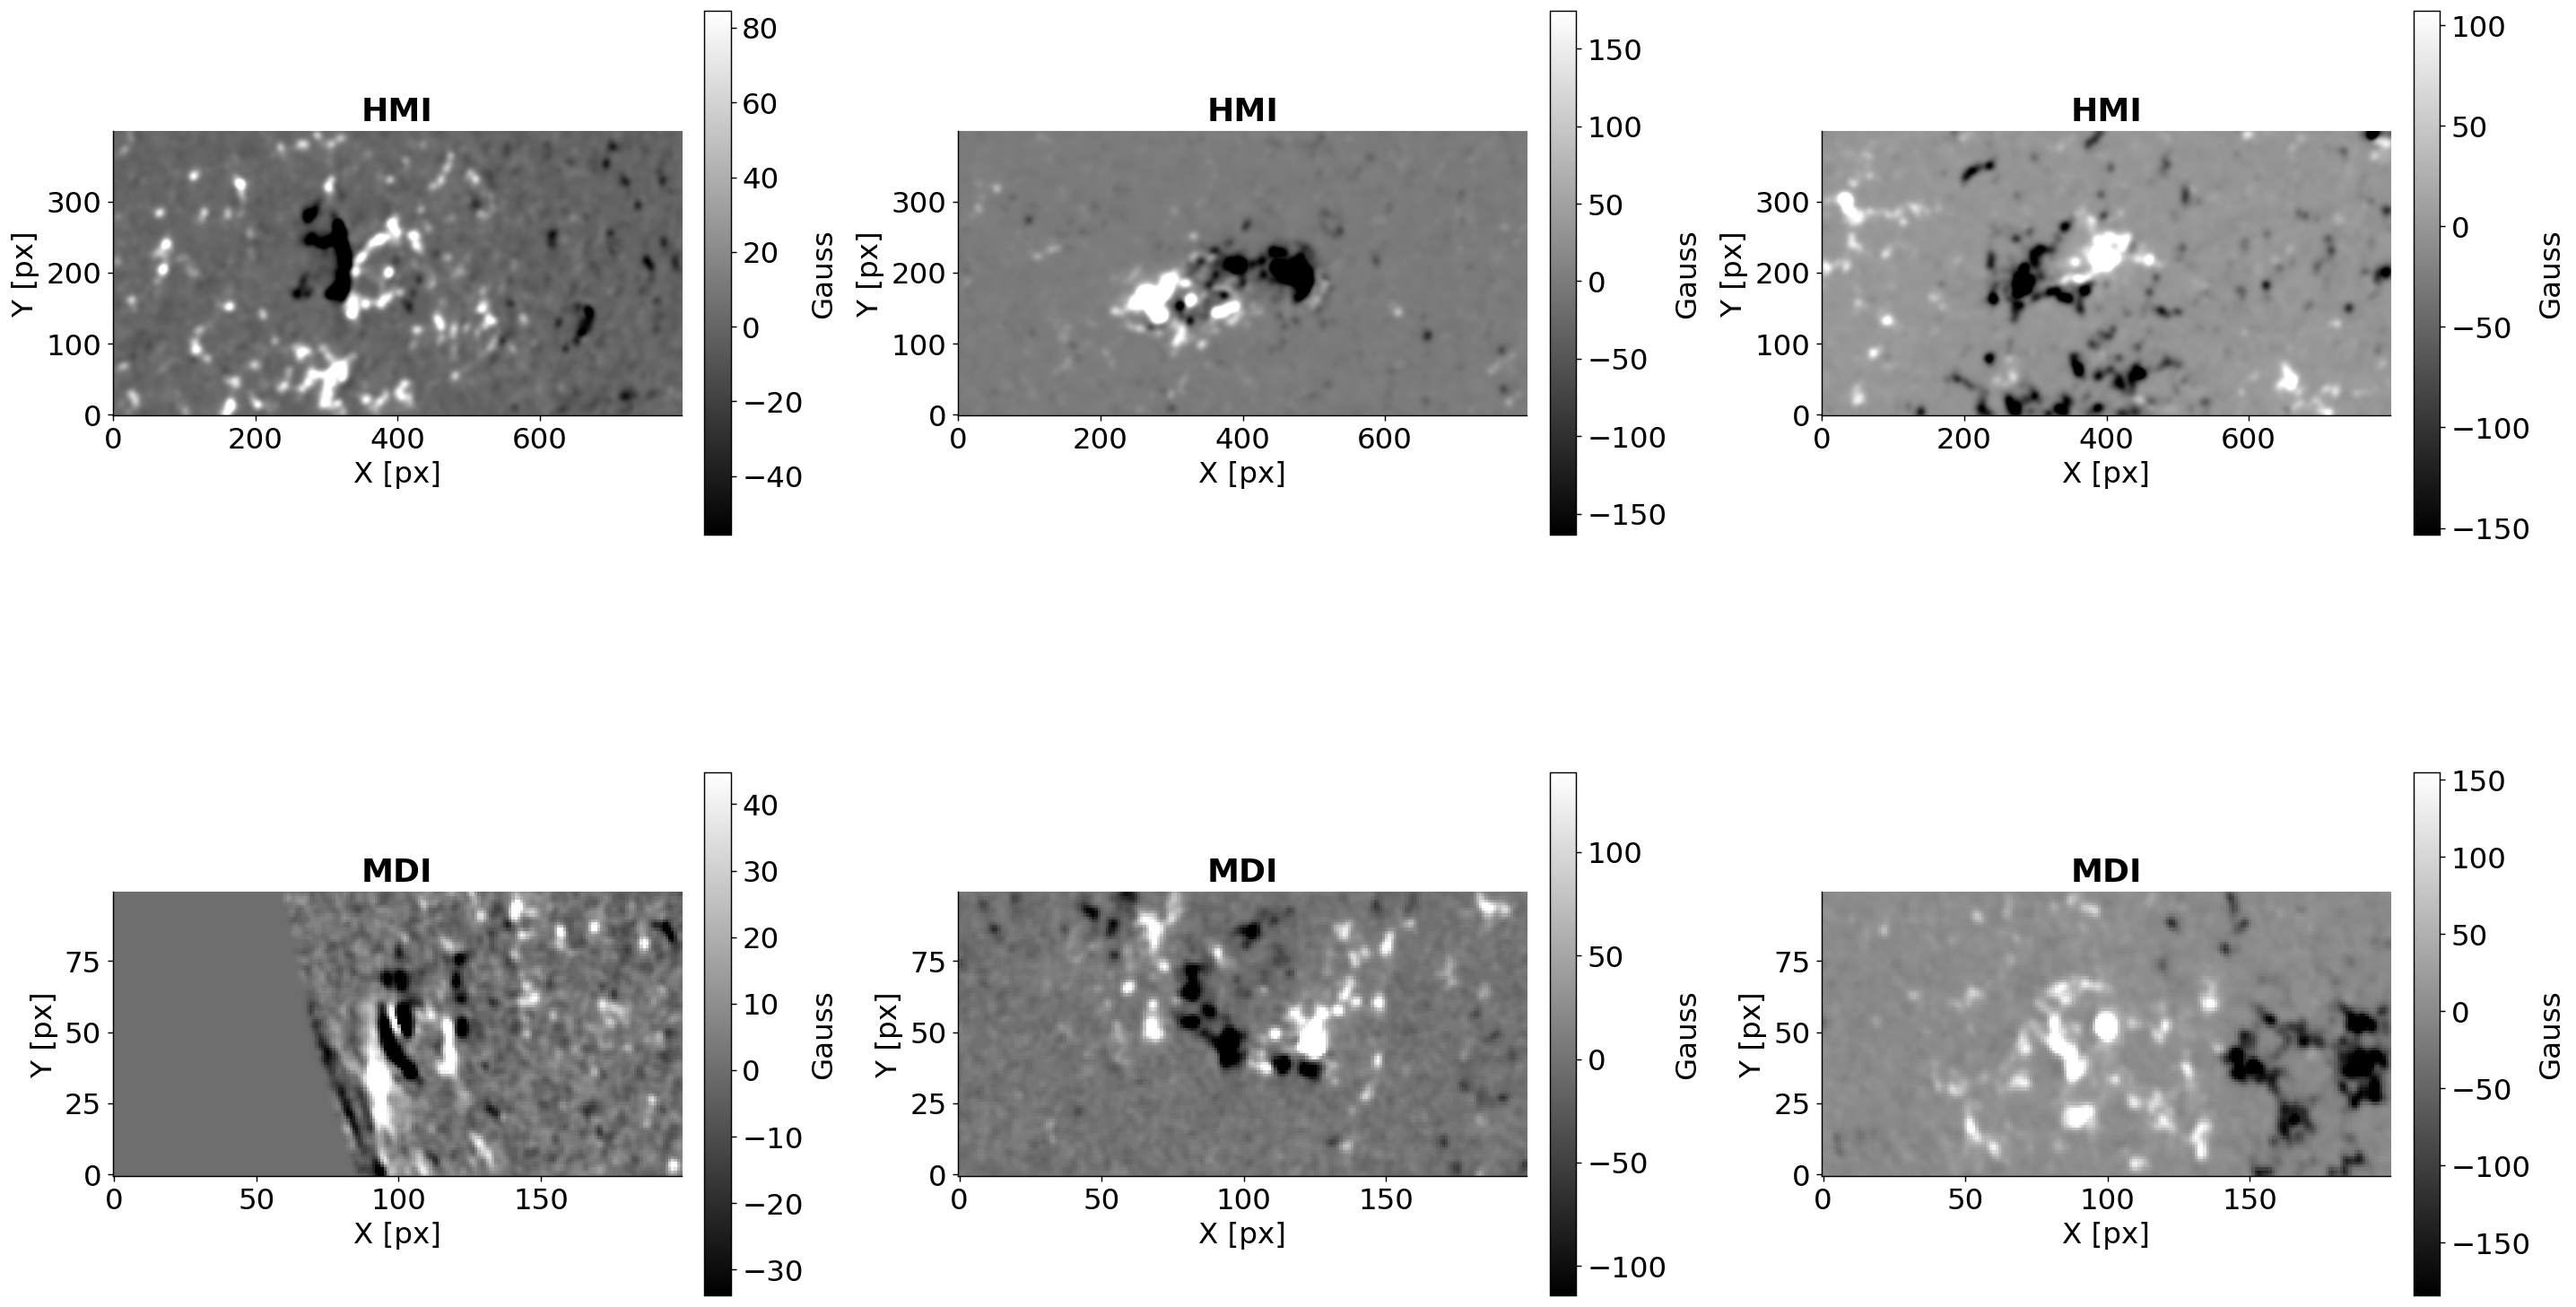

Saved to: notebooks/results/magnetograms_6panel.png


In [6]:
import h5py

# --- Pick 3 random samples for each instrument (reproducible) ---
sample_hmi = timing_df[timing_df['dataset'] == 'HMI'].sample(3, random_state=7)
sample_mdi = timing_df[timing_df['dataset'] == 'MDI'].sample(3, random_state=7)
samples = pd.concat([sample_hmi, sample_mdi])


def load_mag(filepath):
    """Read a magnetogram from an HDF5 file (first 'magnetogram'/'data' key, else first dataset)."""
    with h5py.File(filepath, 'r') as f:
        for key in f.keys():
            if 'magnetogram' in key.lower() or 'data' in key.lower():
                return f[key][:]
        for key in f.keys():
            if isinstance(f[key], h5py.Dataset):
                return f[key][:]
        return None


# --- Global font sizes (also apply to the figures below) ---
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 20,
    'axes.labelsize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
})

fig, axes = plt.subplots(2, 3, figsize=(22, 13), constrained_layout=True)
axes = axes.flatten()

for ax, (_, row) in zip(axes, samples.iterrows()):
    filepath = row['filename']
    if not os.path.exists(filepath):
        ax.text(0.5, 0.5, 'FILE NOT FOUND', ha='center', va='center', fontsize=14)
        ax.set_xticks([]); ax.set_yticks([])
        continue

    data = load_mag(filepath)
    if data is None:
        ax.text(0.5, 0.5, 'NO DATA', ha='center', va='center', fontsize=14)
        ax.set_xticks([]); ax.set_yticks([])
        continue

    # Robust stretch for display
    vmin, vmax = np.nanpercentile(data, [1, 99])
    im = ax.imshow(data, cmap='gray', origin='lower', vmin=vmin, vmax=vmax)
    ax.set_title(row.get('dataset', ''), fontsize=20, fontweight='bold')
    ax.set_xlabel('X [px]', fontsize=18)
    ax.set_ylabel('Y [px]', fontsize=18)
    ax.tick_params(axis='both', which='major', labelsize=18)

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Gauss', fontsize=18)
    cbar.ax.tick_params(labelsize=18)

out_path = os.path.join(OUTPUT_DIR, 'magnetograms_6panel.png')
fig.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved to: {out_path}')

## 3. Threshold optimisation and metrics

For each run (seed × fold × mode), $\tau^*$ is the threshold that maximises the TSS on that run's validation split.
The same criterion is used for both models:

- binary model: score = probability $p_k$ (sigmoid output);
- Poisson model: score = raw rate $\hat\lambda_k$ (monotonic in $1 - e^{-\hat\lambda_k}$).

The TSS depends on the score only through its ranking, so the candidate thresholds are the scores observed on the
validation set: the search is exact and coincides with the ROC point maximising TPR − FPR. Decision rule:
`pred = (score >= tau)`. If several thresholds give the same maximum TSS, `argmax` picks the first one, i.e. the highest
(most conservative).

In [7]:
def best_threshold_tss(y_true, score):
    """tau* = argmax_tau [TPR(tau) - FPR(tau)] over the observed scores.
    Returns NaN if the validation set does not contain both classes."""
    y_true = np.asarray(y_true).astype(int)
    score = np.asarray(score, dtype=float)
    if y_true.sum() == 0 or y_true.sum() == len(y_true):
        return np.nan
    fpr, tpr, thr = roc_curve(y_true, score, drop_intermediate=False)
    return float(thr[int(np.argmax(tpr - fpr))])


tau_records = []
groups = preds_df[preds_df['split'] == 'val'].groupby(['seed', 'fold', 'mode'])
for (seed, fold, mode), sub in groups:
    row = {'seed': seed, 'fold': fold, 'mode': mode}
    for cls in CLASS_NAMES:
        row[f'tau_{cls}'] = best_threshold_tss(
            (sub[f'yt_{cls}'].values >= 0.5).astype(int),
            sub[f'yp_{cls}'].values)
    tau_records.append(row)

tau_df = pd.DataFrame(tau_records)
n_nan = int(tau_df[[f'tau_{c}' for c in CLASS_NAMES]].isna().sum().sum())
print(f'Calibrated {len(tau_df)} runs'
      + (f'  |  WARNING: {n_nan} NaN thresholds (validation set without positives)' if n_nan else ''))
print(tau_df.groupby('mode')[[f'tau_{c}' for c in CLASS_NAMES]].describe().round(4))

Calibrated 100 runs
        tau_C                                                         tau_M  \
        count    mean     std     min     25%     50%     75%     max count   
mode                                                                          
binary   50.0  0.3094  0.0987  0.1105  0.2578  0.2942  0.3839  0.5466  50.0   
poisson  50.0  0.4534  0.0918  0.2584  0.3925  0.4729  0.5188  0.6080  50.0   

                 ...                 tau_X                                 \
           mean  ...     75%     max count    mean     std    min     25%   
mode             ...                                                        
binary   0.1090  ...  0.1247  0.3976  50.0  0.0519  0.1335  0.000  0.0139   
poisson  0.0838  ...  0.1057  0.1729  50.0  0.0185  0.0109  0.001  0.0115   

                                 
            50%     75%     max  
mode                             
binary   0.0204  0.0436  0.9433  
poisson  0.0160  0.0217  0.0541  

[2 rows x 24 columns]


In [8]:
# Merge tau* back into the predictions (re-runnable: existing tau columns are dropped first)
preds_df = (preds_df.drop(columns=[c for c in preds_df.columns if c.startswith('tau_')])
            .merge(tau_df, on=['seed', 'fold', 'mode'], how='left'))

# Binary predictions and outcomes (outcome = 1 for TP, 0 for FN, NaN for negatives)
for cls in CLASS_NAMES:
    preds_df[f'pred_bin_{cls}'] = (preds_df[f'yp_{cls}'] >= preds_df[f'tau_{cls}']).astype(int)
    preds_df[f'true_bin_{cls}'] = (preds_df[f'yt_{cls}'] >= 0.5).astype(int)
    pos = preds_df[f'true_bin_{cls}'] == 1
    preds_df[f'outcome_{cls}'] = np.nan
    preds_df.loc[pos, f'outcome_{cls}'] = preds_df.loc[pos, f'pred_bin_{cls}']

print('Binary predictions and outcomes computed.')

Binary predictions and outcomes computed.


In [9]:
def skills_from_counts(tp, fn, fp, tn):
    tp, fn, fp, tn = float(tp), float(fn), float(fp), float(tn)
    tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    tnr = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    den = (tp + fn) * (fn + tn) + (tp + fp) * (fp + tn)      # HSS2, Eq. (HSS) of the paper
    hss2 = 2.0 * (tp * tn - fp * fn) / den if den > 0 else np.nan
    return {'TPR': tpr, 'TNR': tnr, 'TSS': tpr + tnr - 1.0, 'HSS2': hss2}


def build_metrics_df(preds, classes=('C', 'M', 'X')):
    """TSS, HSS2, TPR, TNR and AUC of every run and split, from the saved predictions
    and the thresholds above. Columns are named {split}_{metric}_{class}."""
    out = {}
    for (seed, fold, mode, split), sub in preds.groupby(['seed', 'fold', 'mode', 'split']):
        rec = out.setdefault((seed, fold, mode), {'seed': seed, 'fold': fold, 'mode': mode})
        for cls in classes:
            y = sub[f'true_bin_{cls}'].values.astype(int)
            p = sub[f'pred_bin_{cls}'].values.astype(int)
            tp = int(((y == 1) & (p == 1)).sum())
            fn = int(((y == 1) & (p == 0)).sum())
            fp = int(((y == 0) & (p == 1)).sum())
            tn = int(((y == 0) & (p == 0)).sum())
            for m, v in skills_from_counts(tp, fn, fp, tn).items():
                rec[f'{split}_{m}_{cls}'] = v
            both = 0 < y.sum() < len(y)
            rec[f'{split}_AUC_{cls}'] = roc_auc_score(y, sub[f'yp_{cls}'].values) if both else np.nan
    return pd.DataFrame(list(out.values()))


metrics_df = build_metrics_df(preds_df)
print(f'metrics_df: {len(metrics_df)} runs ({metrics_df.groupby("mode").size().to_dict()})')

# Sanity check: the formulas above agree with `confusion_skills` on one run
_s, _f, _m = preds_df['seed'].iloc[0], preds_df['fold'].iloc[0], 'poisson'
_sub = preds_df[(preds_df['seed'] == _s) & (preds_df['fold'] == _f) &
                (preds_df['mode'] == _m) & (preds_df['split'] == 'test')]
_ref = confusion_skills(_sub['true_bin_C'].values.astype(int), _sub['pred_bin_C'].values.astype(int))
_row = metrics_df[(metrics_df['seed'] == _s) & (metrics_df['fold'] == _f) &
                  (metrics_df['mode'] == _m)].iloc[0]
print(f"Check vs confusion_skills (C, test): TSS {_row['test_TSS_C']:.4f} vs {_ref['TSS']:.4f}"
      + (f" | HSS2 {_row['test_HSS2_C']:.4f} vs {_ref['HSS2']:.4f}" if 'HSS2' in _ref else ''))

metrics_df: 100 runs ({'binary': 50, 'poisson': 50})
Check vs confusion_skills (C, test): TSS 0.4986 vs 0.4986 | HSS2 0.3343 vs 0.3343


## 4. Occurrence forecasting: Poisson vs. binary

### 4.1 TSS boxplots (`fig:boxplot_TSS`)

Distribution of the metric over the 50 runs (10 seeds × 5 folds) for each split and model, C and M classes side by side.
The X class is left out because its small number of positives makes the metrics unstable. `'HSS2'` and `'AUC'` to
to produce the corresponding figures.

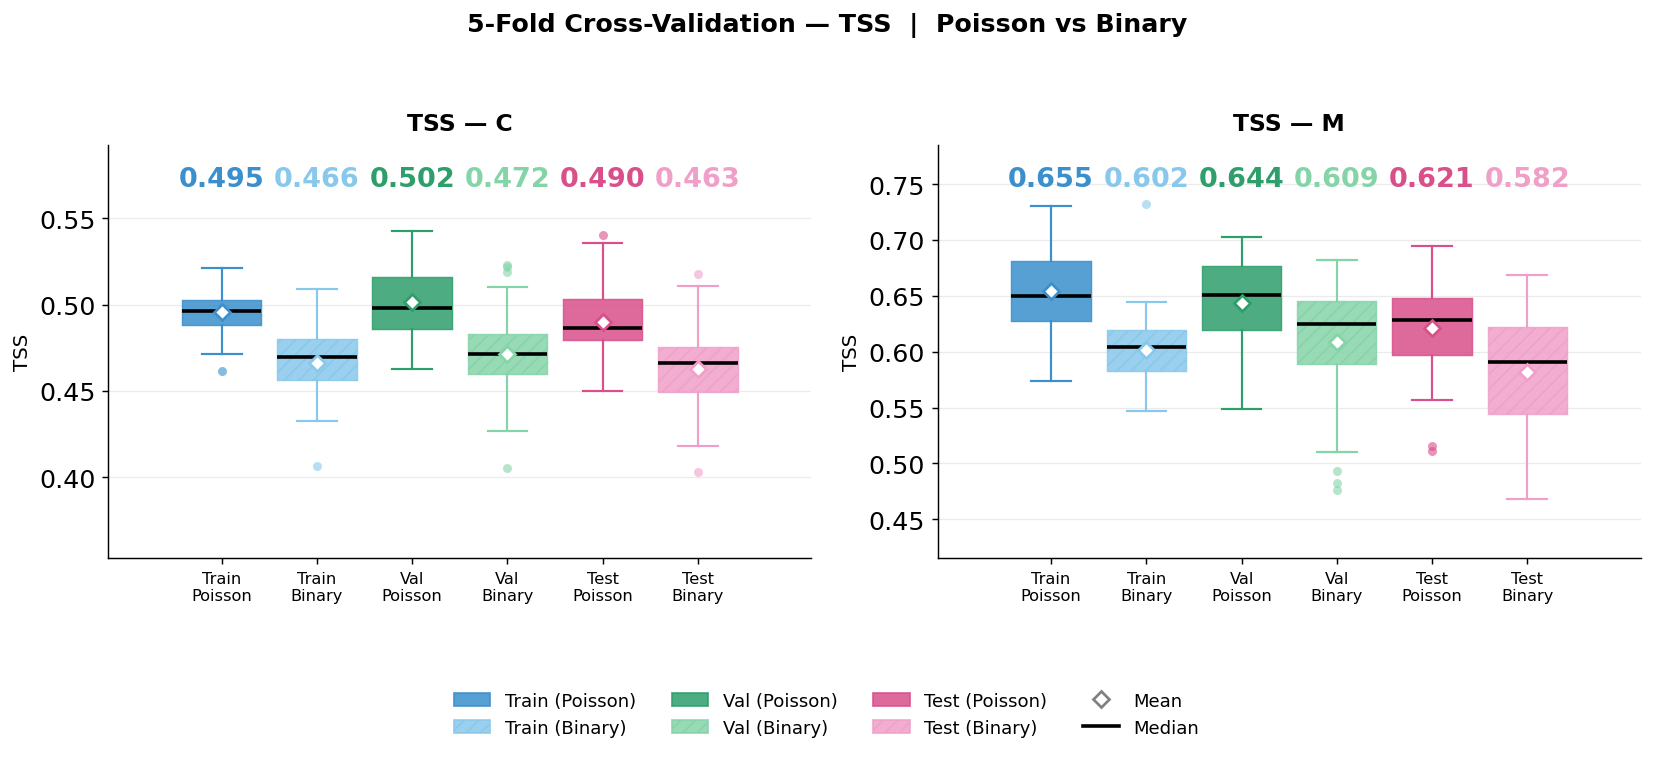

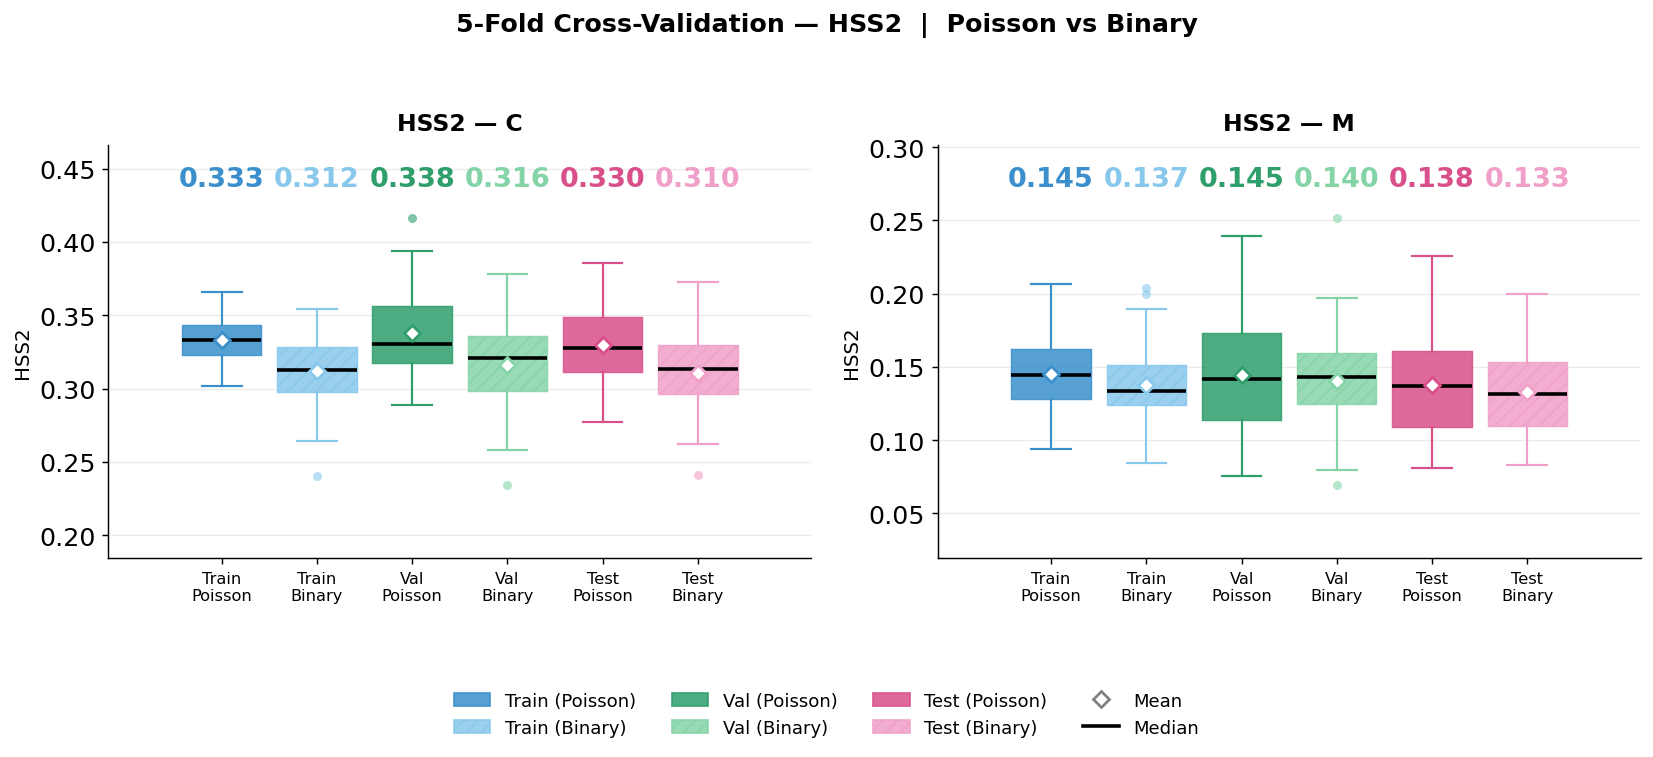

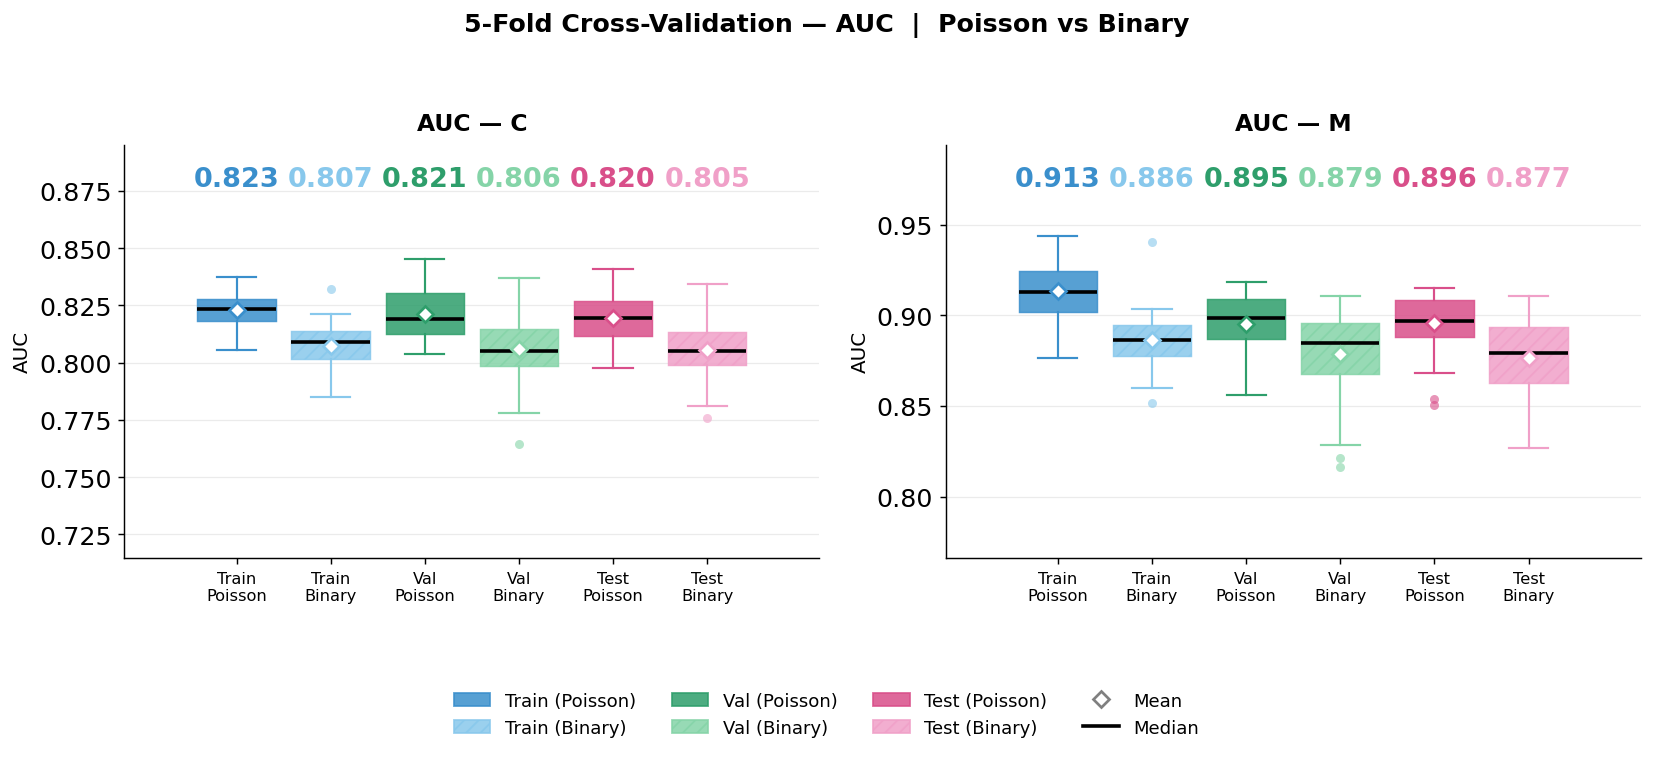

In [10]:
METRICS = ['TSS', 'HSS2', 'AUC']          
CLASSES = ['C', 'M']

BOX_WIDTH = 0.35
SPLIT_GAP = 0.42
mode_labels = {'poisson': 'Poisson', 'binary': 'Binary'}
split_labels = {'train': 'Train', 'val': 'Val', 'test': 'Test'}

keys = list(SPLIT_MODE_STYLES.keys())
n = len(keys)
offsets = np.linspace(-(n - 1) * SPLIT_GAP / 2, (n - 1) * SPLIT_GAP / 2, n)

legend_handles = [
    mpatches.Patch(facecolor=style['color'], hatch=style['hatch'], alpha=0.85,
                   edgecolor=style['color'], label=f'{split_labels[s]} ({mode_labels[m]})')
    for (s, m), style in SPLIT_MODE_STYLES.items()
]
legend_handles.append(Line2D([0], [0], marker='D', color='gray', markerfacecolor='white',
                             markeredgecolor='gray', markeredgewidth=1.5, markersize=6,
                             linewidth=0, label='Mean'))
legend_handles.append(Line2D([0], [0], color='black', linewidth=2, label='Median'))

for metric in METRICS:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)

    for ax, cls in zip(axes, CLASSES):
        all_vals = []
        for ki, (split, mode) in enumerate(keys):
            col = f'{split}_{metric}_{cls}'
            df_mode = metrics_df[metrics_df['mode'] == mode]
            if col not in df_mode.columns:
                continue
            vals = df_mode[col].dropna().values
            if len(vals) == 0:
                continue

            all_vals.extend(vals)
            style = SPLIT_MODE_STYLES[(split, mode)]
            pos = offsets[ki]

            bp = ax.boxplot(
                vals, positions=[pos], widths=BOX_WIDTH, patch_artist=True, notch=False,
                medianprops=dict(color='black', linewidth=2),
                whiskerprops=dict(linewidth=1.2, color=style['color']),
                capprops=dict(linewidth=1.2, color=style['color']),
                flierprops=dict(marker='o', markersize=5, markerfacecolor=style['color'],
                                alpha=0.6, markeredgewidth=0),
                boxprops=dict(linewidth=0.8, edgecolor=style['color']),
            )
            box = bp['boxes'][0]
            box.set_facecolor(style['color'])
            box.set_alpha(0.85)
            box.set_hatch(style['hatch'])

            ax.plot(pos, np.mean(vals), marker='D', color='white',
                    markeredgecolor=style['color'], markeredgewidth=1.5,
                    markersize=6, zorder=5)
            ax.text(pos, 0.95, f'{np.mean(vals):.3f}', transform=ax.get_xaxis_transform(),
                    ha='center', va='top', fontsize=15, color=style['color'], fontweight='bold')

        if all_vals:
            lo, hi = np.min(all_vals), np.max(all_vals)
            margin = max((hi - lo) * 0.20, 0.05)
            ax.set_ylim(lo - margin, hi + margin)

        ax.set_xticks(offsets)
        ax.set_xticklabels([f'{split_labels[s]}\n{mode_labels[m]}' for s, m in keys], fontsize=9)
        ax.axhline(0, color='#aaaaaa', linestyle='--', linewidth=0.8)
        ax.set_title(f'{metric} — {cls}', fontsize=13, fontweight='bold', pad=8)
        ax.set_ylabel(metric, fontsize=11)
        ax.grid(axis='y', alpha=0.25, linewidth=0.7)
        ax.spines[['top', 'right']].set_visible(False)

    fig.legend(handles=legend_handles, loc='lower center', ncol=4, fontsize=10,
               frameon=False, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle(f'5-Fold Cross-Validation — {metric}  |  Poisson vs Binary',
                 fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.18)
    fig.savefig(os.path.join(OUTPUT_DIR, f'boxplot_{metric}_multiseed.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

### 4.2 Paired comparison and AR-level bootstrap

Paired differences $\Delta$ = Poisson − Binary on the same seed × fold runs. The bootstrap resamples the NOAA active
regions (clusters) with the same weights for both models and for all 50 runs; the statistic is the mean over the 50 runs
of the per-run metric. The resulting uncertainty is **conditional on the trained models**: it reflects which ARs are in
the test sets, not seed variability or a new dataset.

In [11]:
def build_ar_tables(cls, split='test'):
    """Per (AR, run) confusion counts [TP, FN, FP, TN] for both models."""
    ar_map = timing_df.drop_duplicates('filename').set_index('filename')['ar_number']
    t = preds_df.loc[preds_df['split'] == split,
                     ['seed', 'fold', 'mode', 'filename', f'true_bin_{cls}', f'pred_bin_{cls}']].copy()
    t['ar'] = t['filename'].map(ar_map)
    t = t.dropna(subset=['ar'])
    t['ar_i'] = pd.factorize(t['ar'])[0]
    t['run_i'] = t.groupby(['seed', 'fold']).ngroup()
    runs = t[['seed', 'fold', 'run_i']].drop_duplicates().sort_values('run_i')
    n_ar, n_run = t['ar_i'].max() + 1, len(runs)
    tabs = {}
    for mode in ['poisson', 'binary']:
        m = t[t['mode'] == mode]
        y, p = m[f'true_bin_{cls}'].values.astype(bool), m[f'pred_bin_{cls}'].values.astype(bool)
        idx = m['ar_i'].values * n_run + m['run_i'].values
        comps = [y & p, y & ~p, ~y & p, ~y & ~p]
        tabs[mode] = np.stack([np.bincount(idx, weights=c.astype(float),
                                           minlength=n_ar * n_run).reshape(n_ar, n_run)
                               for c in comps], axis=-1)            # (n_ar, n_run, 4) = TP, FN, FP, TN
    return tabs, runs[['seed', 'fold']].reset_index(drop=True)


def _skill(c, metric):
    tp, fn, fp, tn = c[..., 0], c[..., 1], c[..., 2], c[..., 3]
    with np.errstate(divide='ignore', invalid='ignore'):
        if metric == 'TSS':
            return tp / (tp + fn) + tn / (tn + fp) - 1
        return 2 * (tp * tn - fp * fn) / ((tp + fn) * (fn + tn) + (tp + fp) * (fp + tn))


def paired_ar_bootstrap(tabs, metric='TSS', n_boot=2000, seed=0, ci=95):
    rng = np.random.default_rng(seed)
    Ap, Ab = tabs['poisson'], tabs['binary']
    n_ar, n_run, _ = Ap.shape
    sp_obs, sb_obs = _skill(Ap.sum(0), metric), _skill(Ab.sum(0), metric)   # per run
    W = rng.multinomial(n_ar, np.full(n_ar, 1.0 / n_ar), size=n_boot).astype(float)
    cp = (W @ Ap.reshape(n_ar, -1)).reshape(n_boot, n_run, 4)
    cb = (W @ Ab.reshape(n_ar, -1)).reshape(n_boot, n_run, 4)
    sp, sb = _skill(cp, metric), _skill(cb, metric)                         # (B, n_run)
    lo, hi = (100 - ci) / 2, 100 - (100 - ci) / 2
    mp, mb, md = np.nanmean(sp, 1), np.nanmean(sb, 1), np.nanmean(sp - sb, 1)
    return dict(
        run_poi=sp_obs, run_bin=sb_obs, run_delta=sp_obs - sb_obs,
        mean_poi=np.nanmean(sp_obs), mean_bin=np.nanmean(sb_obs), mean_delta=np.nanmean(sp_obs - sb_obs),
        ci_poi=np.nanpercentile(mp, [lo, hi]), ci_bin=np.nanpercentile(mb, [lo, hi]),
        ci_delta=np.nanpercentile(md, [lo, hi]),
        n_pos=int(np.nansum(sp_obs > sb_obs)), n_runs=int(np.sum(~np.isnan(sp_obs - sb_obs))))


AR_RES, AR_RUNS = {}, {}
rows, rows_dec = [], []
for cls in CLASS_NAMES:
    tabs, runs = build_ar_tables(cls)
    AR_RUNS[cls] = runs
    for metric in ['TSS', 'HSS2']:
        r = paired_ar_bootstrap(tabs, metric)
        AR_RES[(cls, metric)] = r
        rows.append({'cls': cls, 'metric': metric,
                     'Poisson': r['mean_poi'], 'Binary': r['mean_bin'],
                     'Δ=P−B': r['mean_delta'],
                     'Δ CI95 (AR-bootstrap)': f"[{r['ci_delta'][0]:+.3f}, {r['ci_delta'][1]:+.3f}]",
                     'runs with Δ>0': f"{r['n_pos']}/{r['n_runs']}"})
        d = pd.DataFrame({'seed': runs['seed'], 'fold': runs['fold'], 'delta': r['run_delta']})
        rows_dec.append({'cls': cls, 'metric': metric,
                         'std Δ across runs': d['delta'].std(),
                         'std Δ across seeds (mean over folds)': d.groupby('seed')['delta'].mean().std(),
                         'std Δ across folds (mean over seeds)': d.groupby('fold')['delta'].mean().std()})
print(pd.DataFrame(rows).round(4).to_string(index=False))
print('\nDecomposition of the variability of Δ (point estimates, no bootstrap):')
print(pd.DataFrame(rows_dec).round(4).to_string(index=False))

# Check: the per-run mean rebuilt from the counts matches metrics_df (test)
for cls in ['C', 'M']:
    for mode, key in [('poisson', 'mean_poi'), ('binary', 'mean_bin')]:
        ref = metrics_df.loc[metrics_df['mode'] == mode, f'test_TSS_{cls}'].mean()
        print(f'check {cls} {mode}: bootstrap-obs {AR_RES[(cls, "TSS")][key]:.4f}  metrics_df {ref:.4f}')

cls metric  Poisson  Binary  Δ=P−B Δ CI95 (AR-bootstrap) runs with Δ>0
  C    TSS   0.4897  0.4629 0.0268      [+0.022, +0.031]         42/50
  C   HSS2   0.3296  0.3103 0.0193      [+0.016, +0.023]         36/50
  M    TSS   0.6211  0.5817 0.0394      [+0.029, +0.051]         40/50
  M   HSS2   0.1377  0.1327 0.0049      [+0.002, +0.008]         27/50
  X    TSS   0.7415  0.7003 0.0412      [+0.016, +0.068]         32/50
  X   HSS2   0.0486  0.0427 0.0060      [+0.003, +0.009]         29/50

Decomposition of the variability of Δ (point estimates, no bootstrap):
cls metric  std Δ across runs  std Δ across seeds (mean over folds)  std Δ across folds (mean over seeds)
  C    TSS             0.0267                                0.0085                                0.0136
  C   HSS2             0.0316                                0.0137                                0.0154
  M    TSS             0.0447                                0.0139                                0.0236
  M   H

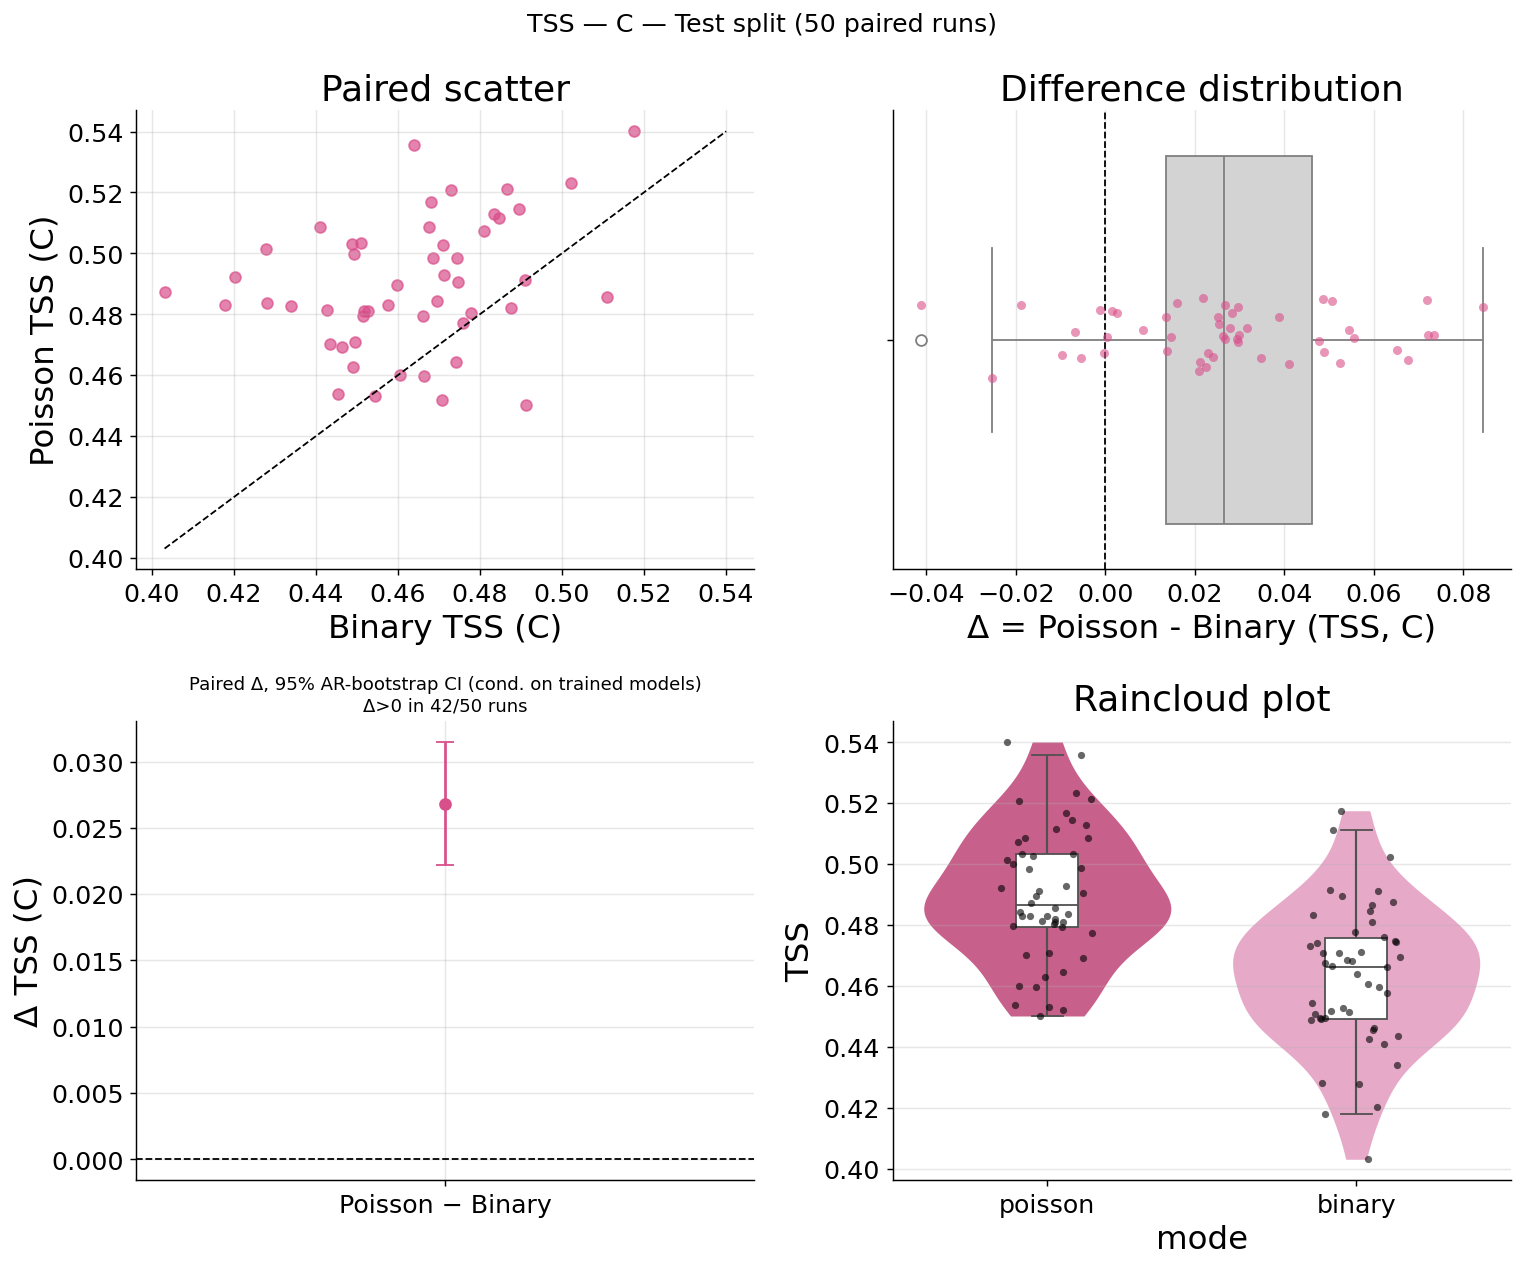

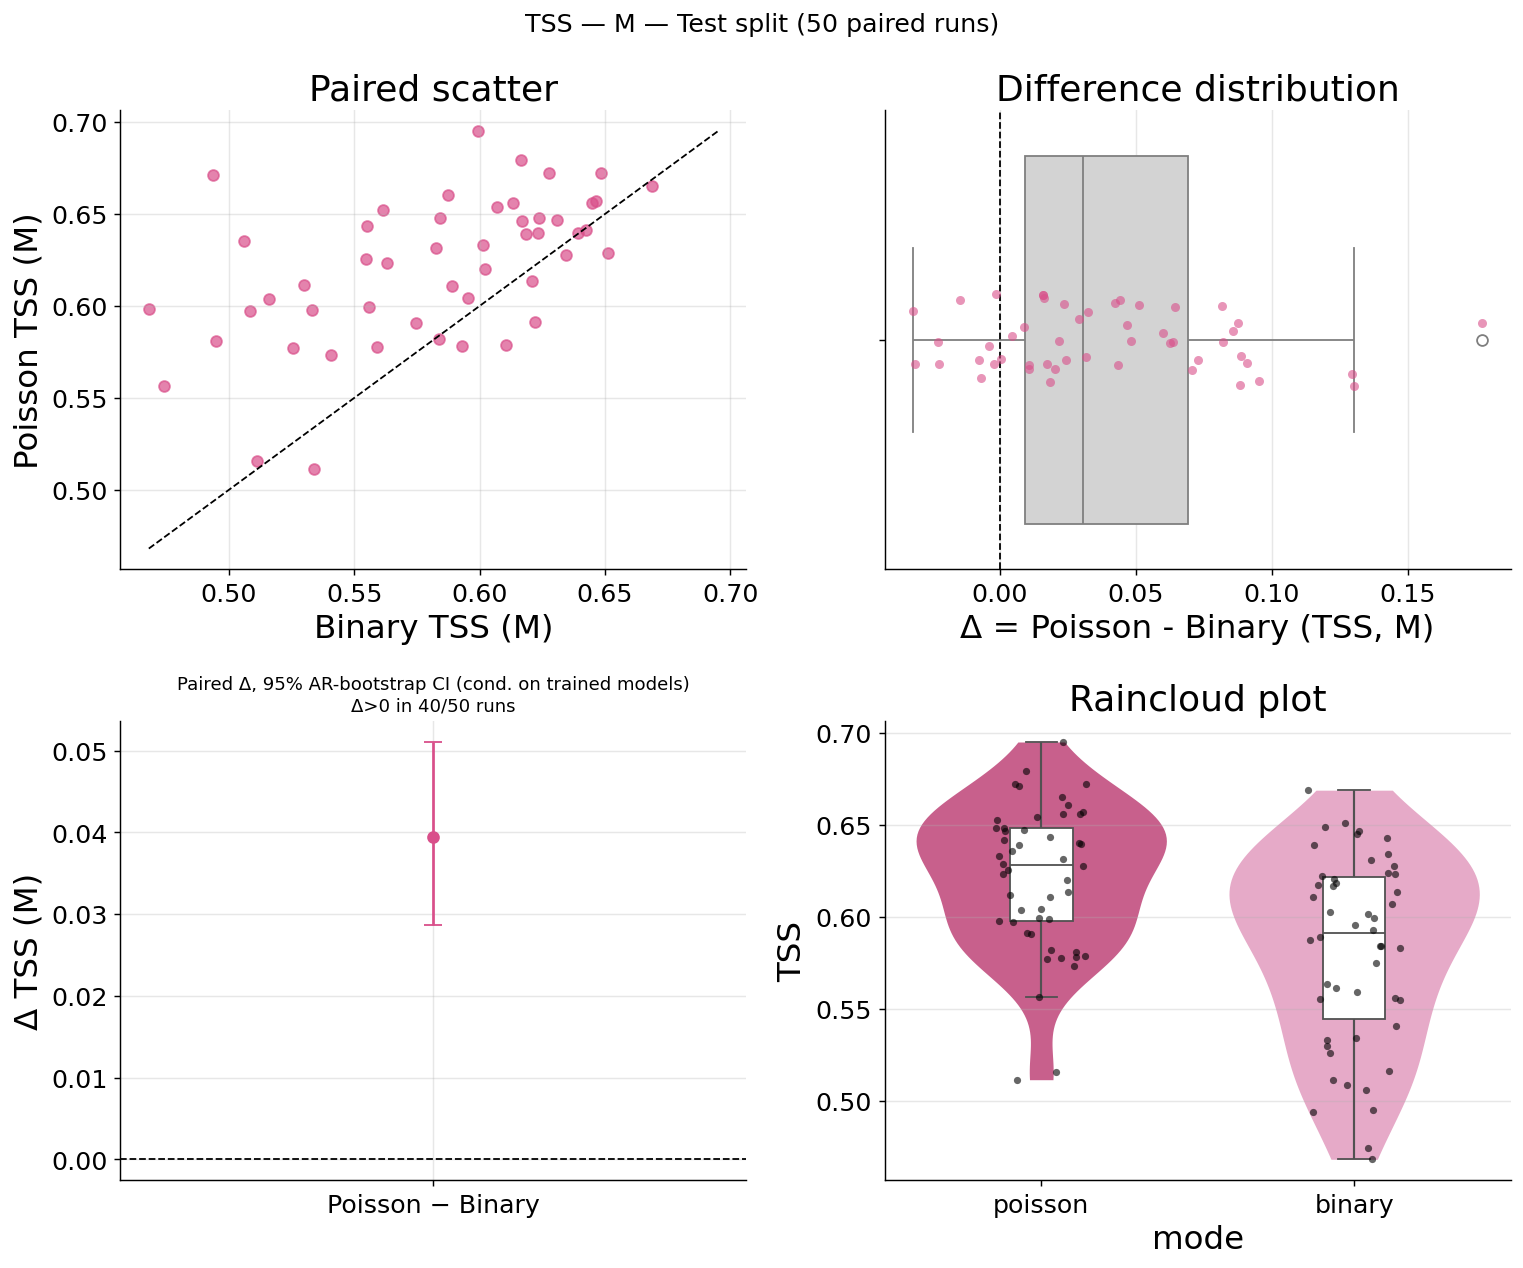

In [12]:
def plot_all_for_class_and_split(metrics_df, cls='C', metric='TSS', split='test'):
    """2x2 figure for a given class, metric and split:
    (1) paired scatter Poisson vs Binary, (2) distribution of the differences,
    (3) paired difference with AR-bootstrap CI, (4) raincloud plot."""
    col = f'{split}_{metric}_{cls}'

    df_p = metrics_df[metrics_df['mode'] == 'poisson'][['seed', 'fold', col]].rename(columns={col: 'poisson'})
    df_b = metrics_df[metrics_df['mode'] == 'binary'][['seed', 'fold', col]].rename(columns={col: 'binary'})
    merged = pd.merge(df_p, df_b, on=['seed', 'fold'], how='inner').dropna()

    long_df = merged.melt(id_vars=['seed', 'fold'], value_vars=['poisson', 'binary'],
                          var_name='mode', value_name=metric)

    color_p = SPLIT_MODE_STYLES[(split, 'poisson')]['color']
    color_b = SPLIT_MODE_STYLES[(split, 'binary')]['color']

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    ax1, ax2, ax3, ax4 = axes.flatten()

    # (1) Paired scatter — Poisson vs Binary
    ax1.scatter(merged['binary'], merged['poisson'], color=color_p, alpha=0.7)
    lims = [min(merged['binary'].min(), merged['poisson'].min()),
            max(merged['binary'].max(), merged['poisson'].max())]
    ax1.plot(lims, lims, 'k--', linewidth=1)
    ax1.set_xlabel(f'Binary {metric} ({cls})')
    ax1.set_ylabel(f'Poisson {metric} ({cls})')
    ax1.set_title('Paired scatter')
    ax1.grid(alpha=0.3)

    # (2) Difference distribution
    merged['delta'] = merged['poisson'] - merged['binary']
    sns.boxplot(x=merged['delta'], color='lightgray', ax=ax2)
    sns.stripplot(x=merged['delta'], color=color_p, alpha=0.6, ax=ax2)
    ax2.axvline(0, color='black', linestyle='--', linewidth=1)
    ax2.set_xlabel(f'Δ = Poisson - Binary ({metric}, {cls})')
    ax2.set_title('Difference distribution')
    ax2.grid(axis='x', alpha=0.3)

    # (3) Paired difference with AR-bootstrap CI
    #     (AR_RES is only available for split='test' and metric in {'TSS', 'HSS2'})
    res = AR_RES[(cls, metric)]
    m, (lo, hi) = res['mean_delta'], res['ci_delta']
    ax3.errorbar(0, m, yerr=[[m - lo], [hi - m]], fmt='o', color=color_p, capsize=5)
    ax3.axhline(0, color='black', ls='--', lw=1)
    ax3.set_xticks([0]); ax3.set_xticklabels(['Poisson − Binary'])
    ax3.set_ylabel(f'Δ {metric} ({cls})')
    ax3.set_title(f"Paired Δ, 95% AR-bootstrap CI (cond. on trained models)\n"
                  f"Δ>0 in {res['n_pos']}/{res['n_runs']} runs", fontsize=10)
    ax3.grid(alpha=0.3)

    # (4) Raincloud plot
    sns.violinplot(data=long_df, x='mode', y=metric, inner=None, cut=0, linewidth=0, scale='width',
                   palette={'poisson': color_p, 'binary': color_b}, ax=ax4)
    sns.boxplot(data=long_df, x='mode', y=metric, width=0.20, showcaps=True,
                boxprops={'facecolor': 'white', 'zorder': 3}, showfliers=False,
                whiskerprops={'linewidth': 1.2}, zorder=3, ax=ax4)
    sns.stripplot(data=long_df, x='mode', y=metric, color='black', size=4,
                  jitter=0.15, alpha=0.6, zorder=4, ax=ax4)
    ax4.set_title('Raincloud plot')
    ax4.grid(axis='y', alpha=0.3)

    fig.suptitle(f'{metric} — {cls} — {split.capitalize()} split ({len(merged)} paired runs)', fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'comparison_{metric}_{cls}_{split}.png'),
                dpi=300, bbox_inches='tight')
    plt.show()


# Test split / TSS / C and M only (`fig:comparison`)
for cls in ['C', 'M']:
    plot_all_for_class_and_split(metrics_df, cls=cls, metric='TSS', split='test')

### 4.3 Runs independent of the hyperparameter search (test fold 0)

The hyperparameters were tuned on a single split (test fold 0, validation fold 2, tuning set drawn from fold 1), so the labels of
folds 1–4 contributed to that choice, and only the runs with test fold 0 are fully independent of it. The 50-run averages above
include the other four folds. Here the metrics and the paired differences are reported separately for the ten seeds with test
fold 0.

These ten runs share the same test set and differ only in weight initialisation, augmentation and batch order, so the spread
across them reflects seed variability only. The AR-bootstrap interval resamples the active regions of test fold 0 and is conditional
on the ten trained networks. With a single test fold the X class has only about 20 positives: its numbers are indicative at best.

In [13]:
FOLD_IND = 0   # test fold whose labels did not enter the hyperparameter search

ind = metrics_df[metrics_df['fold'] == FOLD_IND]
print(f'Runs with test fold {FOLD_IND}: '
      f'{ind.groupby("mode")["seed"].nunique().to_dict()} seeds per mode')

rows = []
for cls in CLASS_NAMES:
    # Per-(AR, run) confusion counts restricted to the runs of fold FOLD_IND and to the ARs of its test set
    tabs, runs = build_ar_tables(cls)
    run_mask = (runs['fold'] == FOLD_IND).values
    sub = {m: t[:, run_mask, :] for m, t in tabs.items()}
    ar_mask = sub['poisson'].sum(axis=(1, 2)) > 0
    sub = {m: t[ar_mask] for m, t in sub.items()}

    for metric in ['TSS', 'HSS2', 'AUC']:
        col = f'test_{metric}_{cls}'
        p = ind[ind['mode'] == 'poisson'].set_index('seed')[col]
        b = ind[ind['mode'] == 'binary'].set_index('seed')[col]
        d = (p - b.reindex(p.index)).dropna()           # paired by seed
        row = {'cls': cls, 'metric': metric,
               'Poisson': f'{p.mean():.3f} ± {p.std():.3f}',
               'Binary': f'{b.mean():.3f} ± {b.std():.3f}',
               'Δ=P−B': round(d.mean(), 4),
               'std Δ (seeds)': round(d.std(), 4),
               'seeds with Δ>0': f'{int((d > 0).sum())}/{len(d)}'}
        if metric in ('TSS', 'HSS2'):
            r = paired_ar_bootstrap(sub, metric)
            row['Δ CI95 (AR-bootstrap)'] = f"[{r['ci_delta'][0]:+.3f}, {r['ci_delta'][1]:+.3f}]"
            # consistency: the mean Δ rebuilt from the counts must equal the one from metrics_df
            assert abs(r['mean_delta'] - d.mean()) < 1e-9, (cls, metric, r['mean_delta'], d.mean())
        else:
            row['Δ CI95 (AR-bootstrap)'] = '–'
        rows.append(row)

print(f'\nTest fold {FOLD_IND} only — mean ± std over seeds (paired by seed)\n')
print(pd.DataFrame(rows).to_string(index=False))

Runs with test fold 0: {'binary': 10, 'poisson': 10} seeds per mode



Test fold 0 only — mean ± std over seeds (paired by seed)

cls metric       Poisson        Binary   Δ=P−B  std Δ (seeds) seeds with Δ>0 Δ CI95 (AR-bootstrap)
  C    TSS 0.491 ± 0.016 0.472 ± 0.013  0.0189         0.0184           9/10      [+0.007, +0.029]
  C   HSS2 0.331 ± 0.019 0.315 ± 0.018  0.0164         0.0195           8/10      [+0.008, +0.025]
  C    AUC 0.823 ± 0.008 0.812 ± 0.010  0.0108         0.0121           9/10                     –
  M    TSS 0.644 ± 0.024 0.632 ± 0.014  0.0125         0.0265           7/10      [-0.003, +0.031]
  M   HSS2 0.156 ± 0.033 0.158 ± 0.013 -0.0023         0.0381           4/10      [-0.008, +0.003]
  M    AUC 0.910 ± 0.006 0.898 ± 0.009  0.0115         0.0116           9/10                     –
  X    TSS 0.782 ± 0.062 0.780 ± 0.052  0.0014         0.0873           4/10      [-0.034, +0.031]
  X   HSS2 0.035 ± 0.013 0.034 ± 0.013  0.0015         0.0191           6/10      [-0.001, +0.004]
  X    AUC 0.966 ± 0.009 0.961 ± 0.014  0.0052   

## 5. Rate calibration

The raw Poisson rate is not a calibrated expected count. To obtain a count estimate for flaring samples, an affine
recalibration in log-space, $\hat\lambda^{\rm cal} = \exp(a + b\log\hat\lambda^{\rm raw})$, is fitted by Poisson maximum
likelihood on the training samples with $y_k > 0$, separately for every (seed, fold) run, so test labels never enter the
fit. It estimates $\mathbb{E}[y_k \mid y_k>0, \mathbf{x}]$ and is applied only to the samples flagged by the thresholded
detector (raw $\hat\lambda$ is kept elsewhere).

In [14]:
def neg_log_lik_poisson(params, log_lam_raw, yt):
    a, b = params
    mu = np.clip(np.exp(a + b * log_lam_raw), EPS, 1e6)
    return -np.sum(yt * np.log(mu) - mu)


def fit_ab(lam_raw, yt, min_pos=10):
    """Poisson maximum-likelihood fit of (a, b) on the samples with y > 0 only.
    With a log link, the Poisson NLL is minimised by the conditional mean:
    mu(x) = exp(a + b*log(lam_raw)) estimates E[Y | Y>0, x]."""
    m = yt > 0
    if m.sum() < min_pos:
        return (np.nan, np.nan)
    res = minimize(neg_log_lik_poisson, x0=[0.0, 1.0],
                   args=(np.log(lam_raw[m] + EPS), yt[m].astype(float)),
                   method='Nelder-Mead',
                   options={'xatol': 1e-6, 'fatol': 1e-6, 'maxiter': 10000})
    return (float(res.x[0]), float(res.x[1]))


# 1. One fit per (seed, fold), using only the training split of that run
train_poi = preds_df[(preds_df['split'] == 'train') & (preds_df['mode'] == 'poisson')]
rows = []
for (seed, fold), sub in train_poi.groupby(['seed', 'fold']):
    r = {'seed': seed, 'fold': fold}
    for cls in CLASS_NAMES:
        r[f'a_{cls}'], r[f'b_{cls}'] = fit_ab(sub[f'yp_{cls}'].values.astype(float),
                                              sub[f'yt_{cls}'].values.astype(float))
    rows.append(r)
params_df = pd.DataFrame(rows)
run_params = {(int(r.seed), int(r.fold), cls): (getattr(r, f'a_{cls}'), getattr(r, f'b_{cls}'))
              for r in params_df.itertuples() for cls in CLASS_NAMES}

# 2. Apply: lam_cal only where pred_bin == 1 (alarms), raw lambda elsewhere
#    (re-runnable: columns from a previous run are dropped first)
drop = [c for c in preds_df.columns
        if c.startswith('lam_cal_') or (c[:2] in ('a_', 'b_') and c[2:] in CLASS_NAMES)]
preds_df = preds_df.drop(columns=drop).merge(params_df, on=['seed', 'fold'], how='left')

is_poi = preds_df['mode'] == 'poisson'
for cls in CLASS_NAMES:
    raw = preds_df[f'yp_{cls}'].values.astype(float)
    a, b = preds_df[f'a_{cls}'].values, preds_df[f'b_{cls}'].values
    cal = np.exp(a + b * np.log(raw + EPS))
    use = is_poi.values & (preds_df[f'pred_bin_{cls}'].values == 1) & ~np.isnan(a)
    preds_df[f'lam_cal_{cls}'] = np.where(use, cal, np.where(is_poi.values, raw, np.nan))

# 3. Fitted coefficients: mean ± std across runs
print('Coefficients (a, b) per run — mean ± std over', len(params_df), 'runs')
for cls in CLASS_NAMES:
    print(f"  {cls}:  a = {params_df[f'a_{cls}'].mean():.3f} ± {params_df[f'a_{cls}'].std():.3f}"
          f"   b = {params_df[f'b_{cls}'].mean():.3f} ± {params_df[f'b_{cls}'].std():.3f}"
          f"   (min b {params_df[f'b_{cls}'].min():.3f}, max b {params_df[f'b_{cls}'].max():.3f})"
          f"   NaN: {int(params_df[f'a_{cls}'].isna().sum())}")

# 4. Training diagnostic: comparing mean y with mean raw lambda is not enough, because even for a
#    Poisson variable E[Y | Y>0] = lambda / (1 - exp(-lambda)) > lambda.
print('\nTrain, observed positives only (y>0), pooled over runs')
print(f"{'cl':>3} {'n':>7} {'mean y':>8} {'mean λraw':>10} {'mean λ/(1-e^-λ)':>16} {'mean λcal':>10}")
trn_pos = preds_df[(preds_df['split'] == 'train') & is_poi]
for cls in CLASS_NAMES:
    pos = trn_pos[trn_pos[f'yt_{cls}'] > 0]
    raw = pos[f'yp_{cls}'].values.astype(float)
    cal = np.exp(pos[f'a_{cls}'].values + pos[f'b_{cls}'].values * np.log(raw + EPS))
    trunc = raw / (1 - np.exp(-raw))
    print(f"{cls:>3} {len(pos):>7} {pos[f'yt_{cls}'].mean():>8.3f} {raw.mean():>10.3f} "
          f"{np.nanmean(trunc):>16.3f} {np.nanmean(cal):>10.3f}")

Coefficients (a, b) per run — mean ± std over 50 runs
  C:  a = 0.750 ± 0.043   b = 0.320 ± 0.049   (min b 0.225, max b 0.421)   NaN: 0
  M:  a = 0.578 ± 0.080   b = 0.203 ± 0.053   (min b 0.095, max b 0.330)   NaN: 0
  X:  a = 0.180 ± 0.082   b = 0.055 ± 0.046   (min b -0.004, max b 0.177)   NaN: 0

Train, observed positives only (y>0), pooled over runs
 cl       n   mean y  mean λraw  mean λ/(1-e^-λ)  mean λcal
  C  138610    2.111      1.352            1.912      2.111
  M   24720    1.458      0.634            1.394      1.458
  X    3080    1.101      0.403            1.247      1.101


In [15]:
# Checks on the test split (independent of the fit).
# The calibrated quantity estimates E[Y | Y>0], so it must be compared on the samples with an alarm AND y>0
# (true positives), not on all alarms.
poi = preds_df[preds_df['mode'] == 'poisson']
tst = poi[poi['split'] == 'test']

print('Test, pooled over runs — per-run calibrated lambda')
print(f"{'cl':>3} {'n alarm':>8} {'n TP':>6} {'y|alarm':>8} {'y|TP':>7} "
      f"{'λraw|TP':>8} {'λ/(1-e^-λ)|TP':>14} {'λcal|TP':>8} {'λcal|alarm':>11}")
for cls in CLASS_NAMES:
    y = tst[f'yt_{cls}'].values
    raw = tst[f'yp_{cls}'].values.astype(float)
    cal = tst[f'lam_cal_{cls}'].values
    al = tst[f'pred_bin_{cls}'].values == 1
    tp = al & (y > 0)
    print(f"{cls:>3} {al.sum():>8} {tp.sum():>6} {y[al].mean():>8.3f} {y[tp].mean():>7.3f} "
          f"{raw[tp].mean():>8.3f} {np.mean(raw[tp] / (1 - np.exp(-raw[tp]))):>14.3f} "
          f"{cal[tp].mean():>8.3f} {cal[al].mean():>11.3f}")

Test, pooled over runs — per-run calibrated lambda
 cl  n alarm   n TP  y|alarm    y|TP  λraw|TP  λ/(1-e^-λ)|TP  λcal|TP  λcal|alarm
  C   105373  35811    0.800   2.354    1.702          2.155    2.384       2.175
  M    73446   7128    0.150   1.542    0.680          1.421    1.514       1.291
  X    36661    916    0.028   1.111    0.248          1.142    1.063       1.009


### Reliability of the raw rate (`tab:reliability`)

Mean predicted rate vs. mean observed count in bins of $\hat\lambda_k$, over all test samples (zeros included), pooled over the 50 runs.

In [16]:
edges = [0, 0.05, 0.1, 0.2, 0.4, 0.7, 1, 2, 4, np.inf]
print('Reliability of raw lambda (test, pooled over the 50 runs): mean lambda vs mean y per bin')
for cls in CLASS_NAMES:
    raw = tst[f'yp_{cls}'].values
    y = tst[f'yt_{cls}'].values
    b = pd.cut(raw, edges, right=False)
    t = (pd.DataFrame({'bin': b, 'lam': raw, 'y': y}).groupby('bin', observed=True)
         .agg(n=('y', 'size'), mean_lam=('lam', 'mean'), mean_y=('y', 'mean')))
    print(f'\n  Class {cls}')
    print(t.round(3).to_string())

Reliability of raw lambda (test, pooled over the 50 runs): mean lambda vs mean y per bin

  Class C
                 n  mean_lam  mean_y
bin                                 
[0.0, 0.05)  56394     0.027   0.025
[0.05, 0.1)  43502     0.073   0.049
[0.1, 0.2)   52239     0.145   0.080
[0.2, 0.4)   52870     0.288   0.143
[0.4, 0.7)   41352     0.535   0.293
[0.7, 1.0)   23519     0.837   0.492
[1.0, 2.0)   32741     1.394   0.855
[2.0, 4.0)   14135     2.690   1.832
[4.0, inf)    2578     5.098   3.296

  Class M
                  n  mean_lam  mean_y
bin                                  
[0.0, 0.05)  219595     0.010   0.005
[0.05, 0.1)   39330     0.072   0.026
[0.1, 0.2)    30470     0.140   0.061
[0.2, 0.4)    16703     0.278   0.150
[0.4, 0.7)     7094     0.522   0.293
[0.7, 1.0)     2652     0.829   0.429
[1.0, 2.0)     2607     1.368   0.711
[2.0, 4.0)      791     2.659   1.224
[4.0, inf)       88     4.725   1.886

  Class X
                  n  mean_lam  mean_y
bin            

## 6. Count forecasting

### 6.1 Count errors against trivial baselines (`tab:count_errors`)

Calibrated counts $\hat y_k = \mathrm{round}(\hat\lambda^{\rm cal}_k)$ are compared with two baselines: always predicting zero and,
among correctly detected flaring samples (TP), a constant equal to the median training count of the positives. All numbers are
computed per run and then averaged over the 50 runs.

In [17]:
# Median training count of the positives, per run and class (constant baseline)
trn = poi[poi['split'] == 'train']
train_median_pos = {}
for (s, f), sub in trn.groupby(['seed', 'fold']):
    for cls in CLASS_NAMES:
        y = sub[f'yt_{cls}'].values
        train_median_pos[(s, f, cls)] = np.median(y[y > 0]) if (y > 0).any() else 0.0


def count_metrics(split='test'):
    rows = []
    for (s, f), sub in poi[poi['split'] == split].groupby(['seed', 'fold']):
        for cls in CLASS_NAMES:
            y = sub[f'yt_{cls}'].values.astype(float)
            raw = sub[f'yp_{cls}'].values.astype(float)
            cal = sub[f'lam_cal_{cls}'].values.astype(float)
            al = sub[f'pred_bin_{cls}'].values == 1
            tp = al & (y > 0)
            med0 = train_median_pos[(s, f, cls)]
            r_cal, r_raw = np.round(cal), np.round(raw)
            rows.append(dict(
                seed=s, fold=f, cls=cls,
                MAE_zero=np.abs(y).mean(),                      # always predict 0
                MAE_raw_round=np.abs(r_raw - y).mean(),
                MAE_cal_round=np.abs(r_cal - y).mean(),         # calibrated count, as defined in the paper
                exact_zero=(y == 0).mean(),
                exact_cal=(r_cal == y).mean(),
                MAE_cal_TP=np.abs(r_cal - y)[tp].mean() if tp.any() else np.nan,
                MAE_const_TP=np.abs(med0 - y)[tp].mean() if tp.any() else np.nan))  # constant = train median of positives
    return pd.DataFrame(rows)


cm = count_metrics('test')
print(f'Test split — mean ± std over {cm.groupby(["seed", "fold"]).ngroups} runs\n')
summ = cm.drop(columns=['seed', 'fold']).groupby('cls').agg(['mean', 'std'])
print(summ.round(3).T.to_string())

# Reading guide:
#  - MAE_cal_round vs MAE_zero (and exact_cal vs exact_zero): if the calibrated count does worse than
#    "always 0", it must not be presented as skill on the count (each false alarm costs ~1-2 counts).
#  - MAE_cal_TP vs MAE_const_TP: once the flare is detected, does the calibrated rate beat a constant?

Test split — mean ± std over 50 runs

cls                     C      M      X
MAE_zero      mean  0.318  0.039  0.004
              std   0.025  0.006  0.001
MAE_raw_round mean  0.452  0.056  0.006
              std   0.045  0.015  0.003
MAE_cal_round mean  0.681  0.252  0.113
              std   0.046  0.048  0.050
exact_zero    mean  0.850  0.973  0.997
              std   0.003  0.002  0.001
exact_cal     mean  0.647  0.778  0.887
              std   0.024  0.046  0.050
MAE_cal_TP    mean  1.419  0.629  0.106
              std   0.068  0.079  0.038
MAE_const_TP  mean  1.355  0.534  0.106
              std   0.167  0.122  0.038


### 6.2 Count-error histogram (`fig:err_hist`)

══════════════════════════════════════════════════════════════════════
SPLIT = test   (n samples = 319330, pooled over 10 seeds x 5 folds)
══════════════════════════════════════════════════════════════════════
  Class C:  mean |err| = 0.681   median |err| = 0.0   max |err| = 20
    counts per bin (0, 1, 2, 3, 4+):  [206409, 30392, 69053, 10478, 2998]
  Class M:  mean |err| = 0.253   median |err| = 0.0   max |err| = 7
    counts per bin (0, 1, 2, 3, 4+):  [248230, 62118, 8623, 197, 162]
  Class X:  mean |err| = 0.113   median |err| = 0.0   max |err| = 3
    counts per bin (0, 1, 2, 3, 4+):  [283337, 35977, 14, 2, 0]



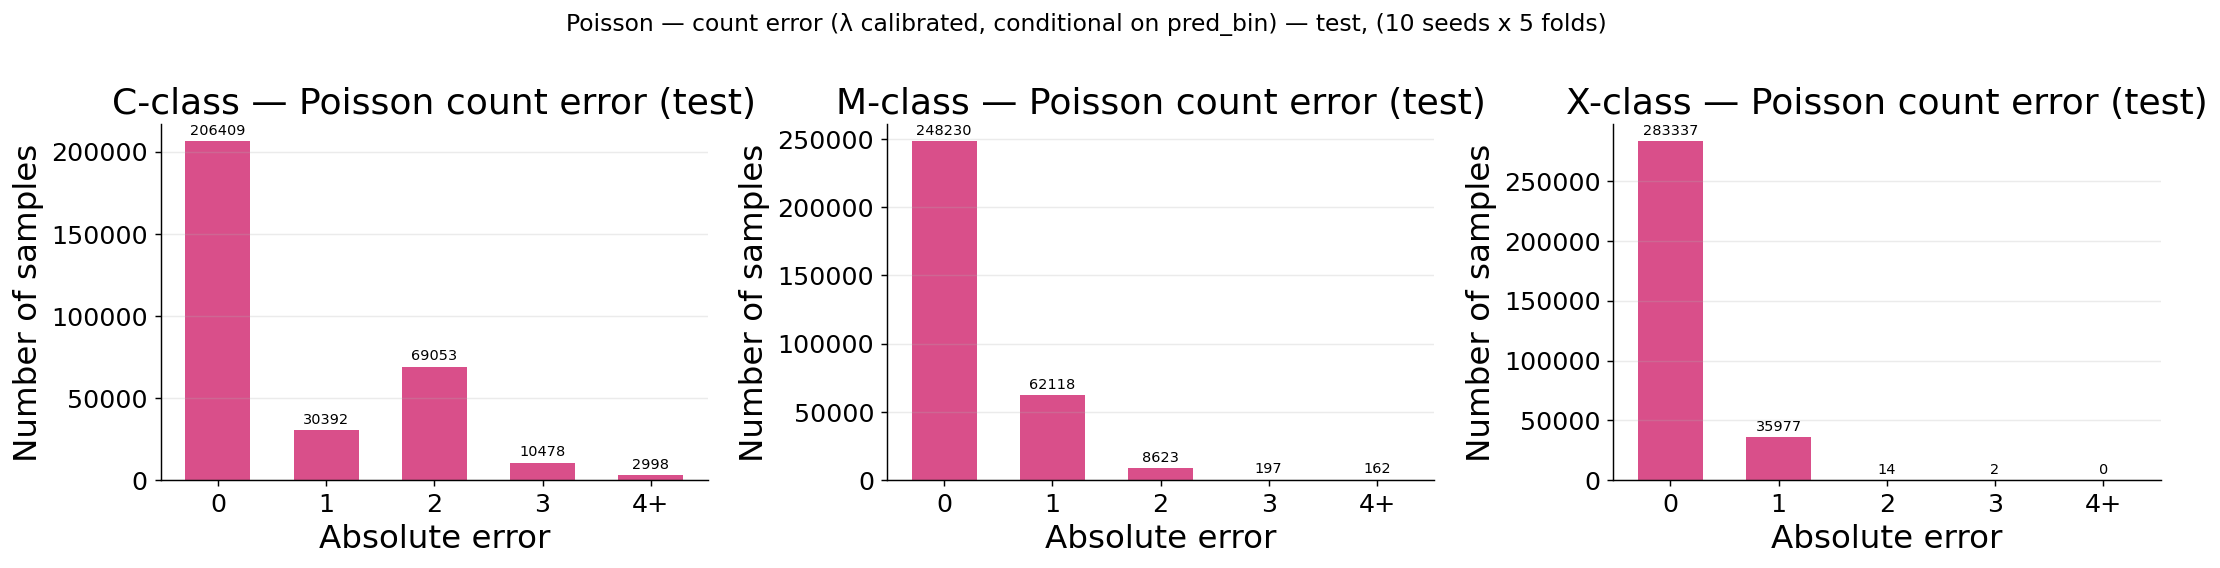

In [18]:
MAX_ERR_BIN = 4  # errors >= this value are grouped in the last bar ("4+")
bin_labels = [str(i) for i in range(MAX_ERR_BIN)] + [f'{MAX_ERR_BIN}+']

for ERR_SPLIT in ['test']:     # add 'train', 'val' for the other splits
    color_poi = SPLIT_MODE_STYLES[(ERR_SPLIT, 'poisson')]['color']
    sub = preds_df[(preds_df['split'] == ERR_SPLIT) & (preds_df['mode'] == 'poisson')].copy()

    print('═' * 70)
    print(f'SPLIT = {ERR_SPLIT}   (n samples = {len(sub)}, pooled over 10 seeds x 5 folds)')
    print('═' * 70)

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=False)
    for ax, cls in zip(axes, CLASS_NAMES):
        yt_true = sub[f'yt_{cls}'].round().astype(int)

        # Calibrated lambda only where pred_bin == 1, raw lambda elsewhere (see Section 5)
        lam_calib = sub[f'lam_cal_{cls}'].values.astype(float)
        pred_poi = np.round(lam_calib).astype(int)

        err = np.abs(pred_poi - yt_true.values)
        counts = pd.Series(err).clip(upper=MAX_ERR_BIN).value_counts().reindex(range(MAX_ERR_BIN + 1), fill_value=0)

        print(f'  Class {cls}:  mean |err| = {err.mean():.3f}   median |err| = {np.median(err):.1f}   max |err| = {err.max()}')
        print(f"    counts per bin ({', '.join(bin_labels)}):  {counts.values.tolist()}")

        x = np.arange(len(bin_labels))
        bars = ax.bar(x, counts.values, width=0.6, color=color_poi)
        ax.bar_label(bars, fontsize=8, padding=2)
        ax.set_xticks(x)
        ax.set_xticklabels(bin_labels)
        ax.set_xlabel('Absolute error')
        ax.set_ylabel('Number of samples')
        ax.set_title(f'{cls}-class — Poisson count error ({ERR_SPLIT})')
        ax.grid(axis='y', alpha=0.25)

    print()
    fig.suptitle(f'Poisson — count error (λ calibrated, conditional on pred_bin) — {ERR_SPLIT}, (10 seeds x 5 folds)', fontsize=13)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'count_error_hist_poisson_{ERR_SPLIT}_total.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

### 6.3 Case studies (`fig:lambda_12673_a`, `fig:lambda_9236`, `fig:lambda_12109`)

First, a per-AR table (test split, averaged over the 10 seeds) used to select the case studies explicitly: the most active
ARs, the worst misses and the worst false alarms. The selection is illustrative, not random.

In [19]:
tk = timing_df[['filename', 'ar_number', 'sample_time']].drop_duplicates('filename')
cols = ['seed', 'fold', 'mode', 'filename'] + [f'{p}_{c}' for p in ('yt', 'yp', 'pred_bin', 'lam_cal')
                                               for c in CLASS_NAMES]
cols = [c for c in cols if c in preds_df.columns]
df_cs = (preds_df.loc[preds_df['split'] == 'test', cols].merge(tk, on='filename', how='left'))
df_cs['sample_time'] = pd.to_datetime(df_cs['sample_time'])


def ar_summary(cls):
    """Per-AR hit rate (on days with a flare) and false-alarm rate (on days without), by model."""
    hit, fa = {}, {}
    for mode, sub in df_cs.groupby('mode'):
        pos, neg = sub[sub[f'yt_{cls}'] > 0], sub[sub[f'yt_{cls}'] == 0]
        hit[mode] = pos.groupby('ar_number')[f'pred_bin_{cls}'].mean()
        fa[mode] = neg.groupby('ar_number')[f'pred_bin_{cls}'].mean()
    base = df_cs.drop_duplicates('filename')
    info = pd.DataFrame({
        'n_days': base.groupby('ar_number').size(),
        'n_pos_days': base[base[f'yt_{cls}'] > 0].groupby('ar_number').size(),
        'n_flares': base.groupby('ar_number')[f'yt_{cls}'].sum(),
        'max_daily': base.groupby('ar_number')[f'yt_{cls}'].max()}).fillna(0)
    return info.join(pd.DataFrame({'hit_poi': hit['poisson'], 'hit_bin': hit['binary'],
                                   'FA_poi': fa['poisson'], 'FA_bin': fa['binary']}))


CLS_SEL = 'M'
S = ar_summary(CLS_SEL)
print(f'── {CLS_SEL}: most active ARs (n_flares)')
print(S.sort_values('n_flares', ascending=False).head(8).round(2).to_string())

act = S[S['n_pos_days'] >= 3].copy()
act['hit_mean'] = act[['hit_poi', 'hit_bin']].mean(axis=1)
print(f'\n── {CLS_SEL}: worst misses (>=3 positive days, lowest mean hit rate)')
print(act.sort_values('hit_mean').head(8).round(2).to_string())

print(f'\n── {CLS_SEL}: worst false alarms (ARs without {CLS_SEL}-class flares, >=5 days)')
print(S[(S['n_pos_days'] == 0) & (S['n_days'] >= 5)].sort_values('FA_poi', ascending=False).head(8).round(2).to_string())

── M: most active ARs (n_flares)
           n_days  n_pos_days  n_flares  max_daily  hit_poi  hit_bin  FA_poi  FA_bin
ar_number                                                                           
12192          12         9.0      30.0        6.0     1.00     0.98    1.00    1.00
10375          13         7.0      26.0        9.0     0.94     0.91    0.83    0.48
12673          12         6.0      26.0        7.0     1.00     1.00    0.25    0.08
11515          10         5.0      26.0        9.0     1.00     1.00    0.98    0.96
10656          12         6.0      23.0        7.0     1.00     1.00    0.67    0.70
11967          13         8.0      22.0        6.0     1.00     1.00    1.00    1.00
12297          13        10.0      20.0        5.0     1.00     0.99    0.97    0.97
12422          11         6.0      17.0        6.0     1.00     1.00    0.60    0.58

── M: worst misses (>=3 positive days, lowest mean hit rate)
           n_days  n_pos_days  n_flares  max_daily  hit

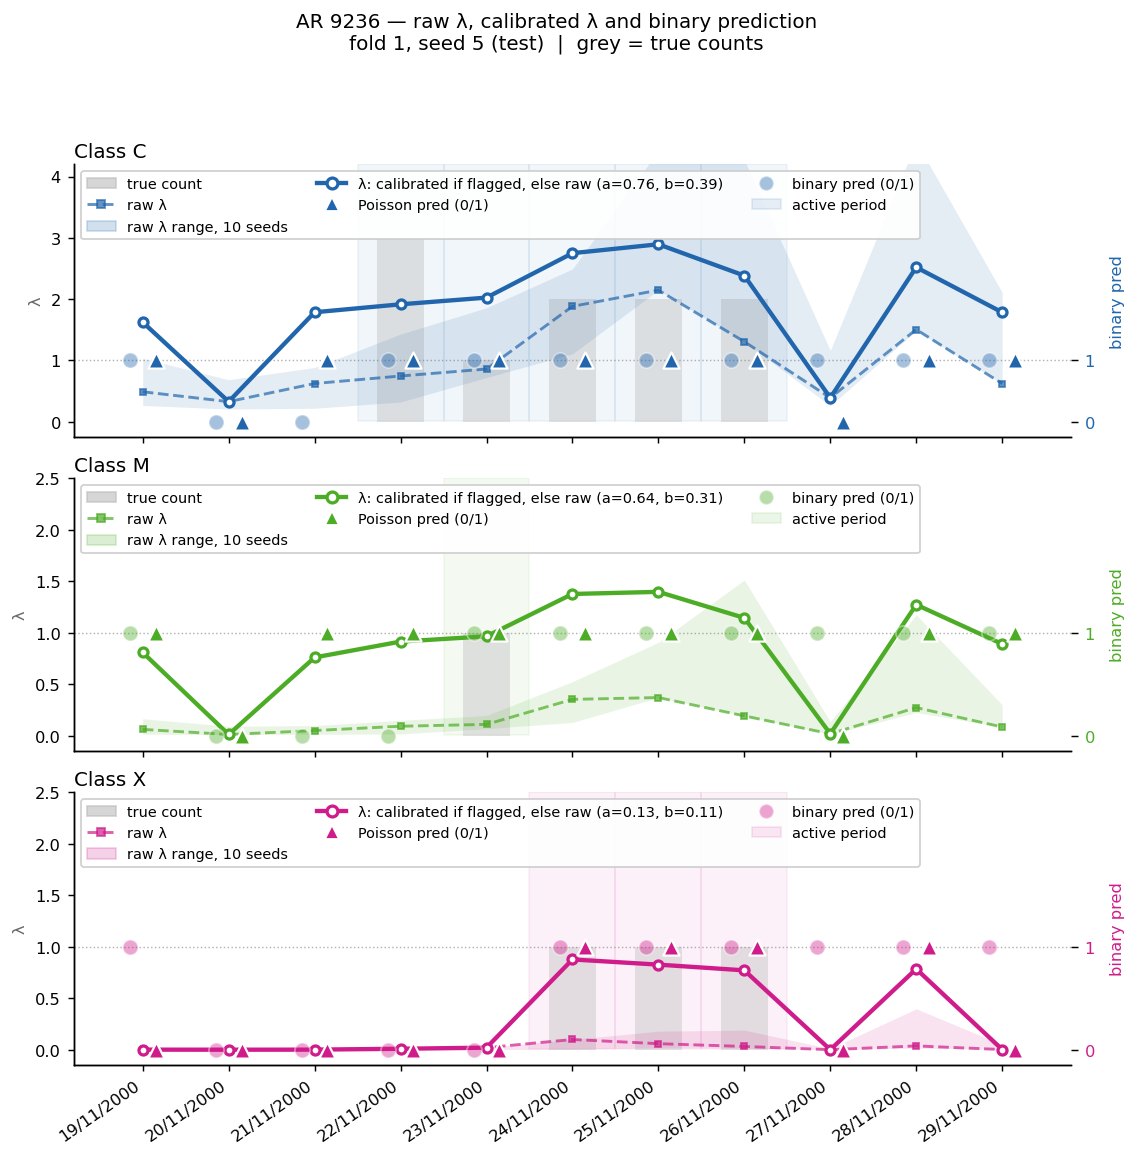

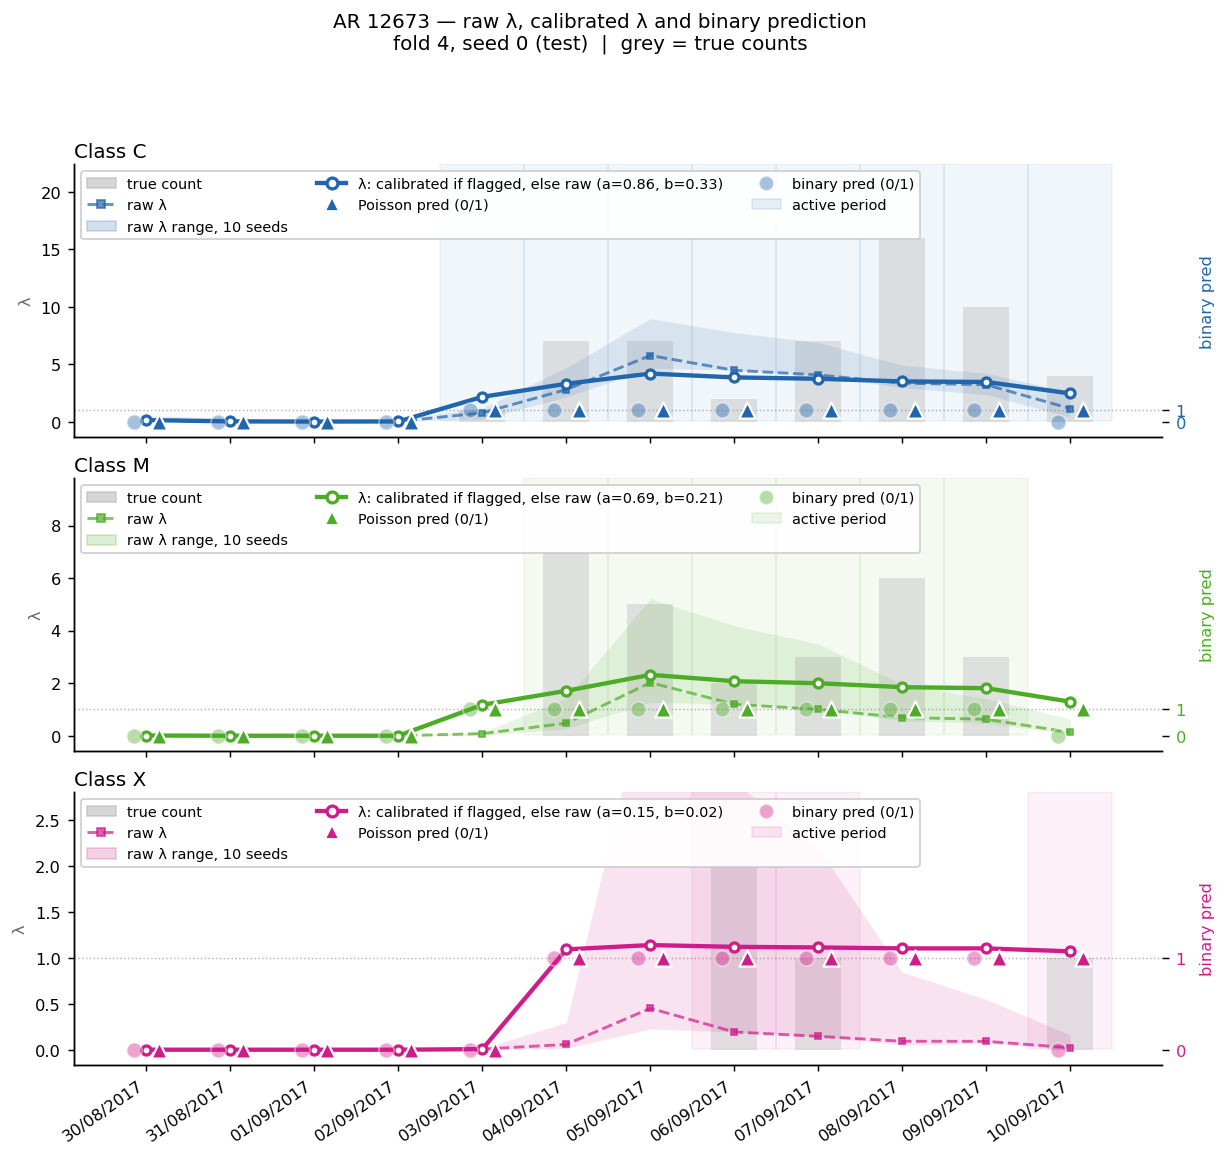

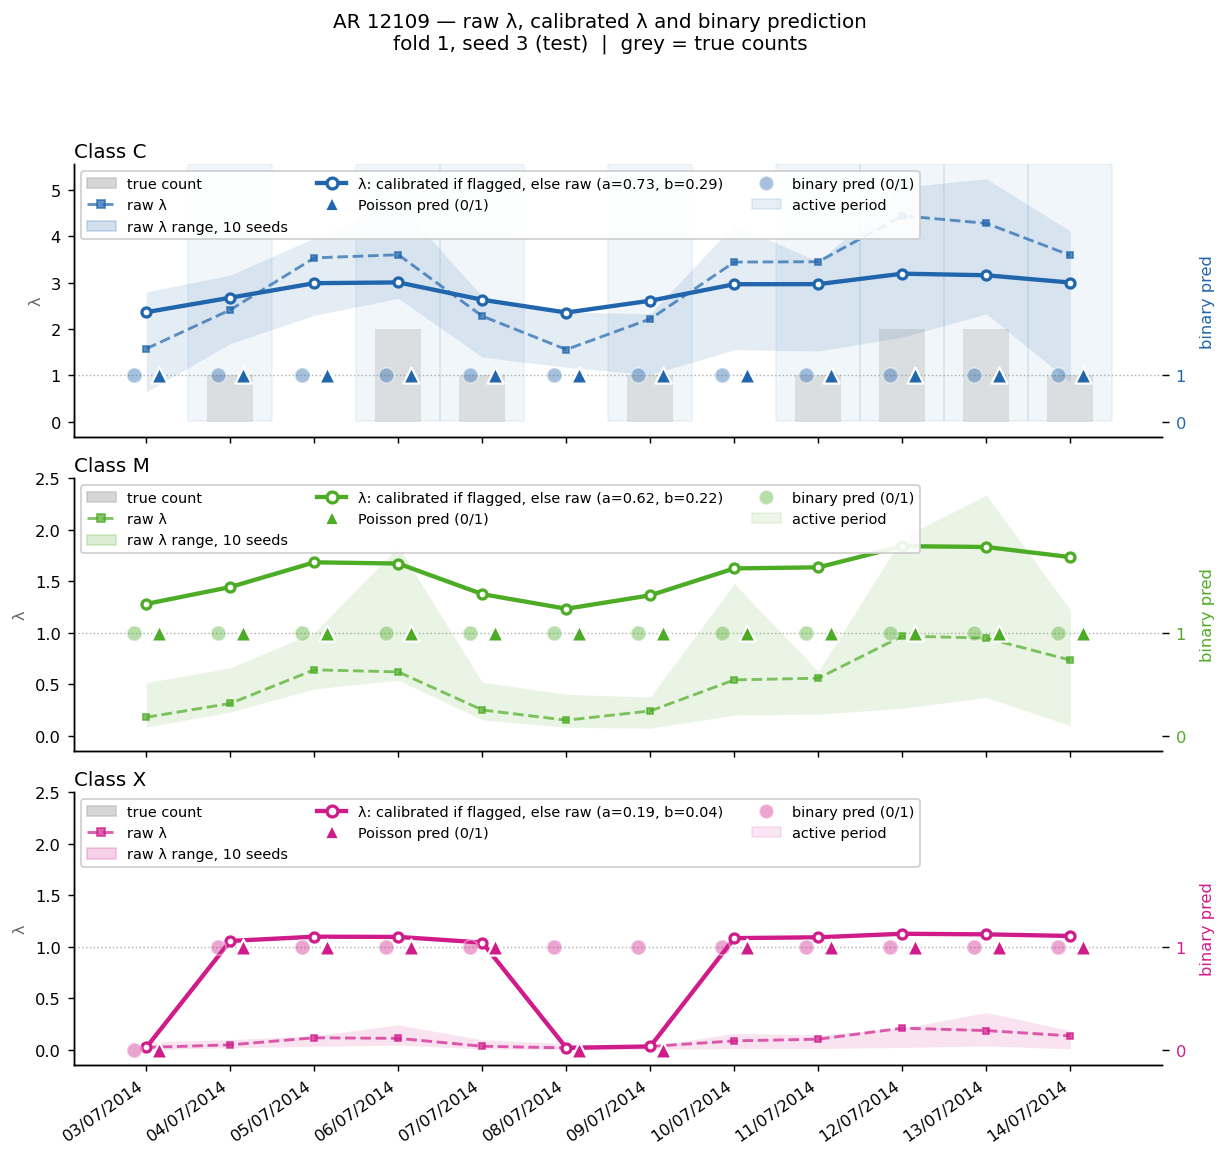

In [20]:
CLS_COLOR = {'C': '#2166ac', 'M': '#4dac26', 'X': '#d01c8b'}


def plot_ar_calib(ar, seed, show_band=True, save=True, outdir=None):
    """Daily case study of one AR (test split, one seed): true counts (grey bars), raw lambda (dashed, band = range
    over the 10 seeds), calibrated lambda (solid) and Poisson / binary detections (markers)."""
    outdir = outdir or OUTPUT_DIR
    df_ar = df_cs[df_cs['ar_number'] == ar]
    df_s = df_ar[df_ar['seed'] == seed]
    folds = df_s['fold'].unique()
    assert len(folds) == 1, f'AR {ar} appears in {len(folds)} folds for seed {seed}'
    fold = folds[0]
    df_bin = df_s[df_s['mode'] == 'binary'].sort_values('sample_time').reset_index(drop=True)
    df_poi = df_s[df_s['mode'] == 'poisson'].sort_values('sample_time').reset_index(drop=True)
    times = df_poi['sample_time'].values
    x = np.arange(len(times))
    xlabels = [pd.Timestamp(t).round('D').strftime('%d/%m/%Y') for t in times]
    band = (df_ar[df_ar['mode'] == 'poisson'].groupby('sample_time')[[f'yp_{c}' for c in CLASS_NAMES]]
            .agg(['min', 'max']).reindex(df_poi['sample_time']))

    fig, axes = plt.subplots(3, 1, figsize=(max(9, len(times) * 0.9), 9), sharex=True,
                             gridspec_kw={'hspace': 0.15})
    fig.suptitle(f'AR {ar} — raw λ, calibrated λ and binary prediction\n'
                 f'fold {fold}, seed {seed} (test)  |  grey = true counts', fontsize=11, y=1.01)
    hoff = 0.15
    for ax, cls in zip(axes, CLASS_NAMES):
        col = CLS_COLOR[cls]
        yt, lam_raw, lam_cal = (df_poi[f'yt_{cls}'].values, df_poi[f'yp_{cls}'].values,
                                df_poi[f'lam_cal_{cls}'].values)
        pred_bin, pred_poi = df_bin[f'pred_bin_{cls}'].values, df_poi[f'pred_bin_{cls}'].values
        ymax = max(yt.max() * 1.4, lam_cal.max() * 1.3, lam_raw.max() * 1.25, 2.5)

        ax.bar(x, yt, width=0.55, color='#bbbbbb', alpha=0.4, zorder=1)
        for i, v in enumerate(yt):
            if v > 0:
                ax.axvspan(i - 0.5, i + 0.5, color=col, alpha=0.06, zorder=0, ymin=0.06, ymax=1.0)
        ax.axhline(1.0, color='grey', lw=0.8, ls=':', alpha=0.6, zorder=2)
        if show_band:
            ax.fill_between(x, band[(f'yp_{cls}', 'min')].values, band[(f'yp_{cls}', 'max')].values,
                            color=col, alpha=0.12, zorder=2, linewidth=0)
        ax.plot(x, lam_raw, color=col, lw=1.6, ls='--', alpha=0.7, marker='s', markersize=3.5, zorder=3)
        ax.plot(x, lam_cal, color=col, lw=2.4, zorder=4, marker='o', markersize=5,
                markerfacecolor='white', markeredgewidth=1.8)
        ax.scatter(x - hoff, pred_bin.astype(float), s=70, color=col, alpha=0.4, zorder=5,
                   marker='o', edgecolors='white', linewidths=1.0)
        ax.scatter(x + hoff, pred_poi.astype(float), s=80, color=col, zorder=5,
                   marker='^', edgecolors='white', linewidths=1.2)
        ax.set_ylim(-ymax * 0.06, ymax)
        ax.set_ylabel('λ', fontsize=9, color='dimgray')
        ax.tick_params(axis='y', labelsize=9)
        ax.set_title(f'Class {cls}', fontsize=11, loc='left', pad=4)
        ax2 = ax.twinx()
        ax2.set_ylim(-ymax * 0.06, ymax)
        ax2.set_yticks([0, 1]); ax2.set_yticklabels(['0', '1'], fontsize=9, color=col)
        ax2.tick_params(axis='y', labelcolor=col, length=4)
        ax2.set_ylabel('binary pred', fontsize=9, color=col, labelpad=8)

        a_val, b_val = run_params[(int(seed), int(fold), cls)]
        handles = [
            mpatches.Patch(color='#bbbbbb', alpha=0.6, label='true count'),
            Line2D([0], [0], color=col, lw=1.6, ls='--', marker='s', markersize=4, alpha=0.7, label='raw λ'),
            Line2D([0], [0], color=col, lw=2.4, marker='o', markerfacecolor='white', markeredgewidth=1.8,
                label=f'λ: calibrated if flagged, else raw (a={a_val:.2f}, b={b_val:.2f})'),
            Line2D([0], [0], color=col, lw=0, marker='^', markersize=8, markerfacecolor=col,
                   markeredgecolor='white', label='Poisson pred (0/1)'),
            Line2D([0], [0], color=col, lw=0, marker='o', markersize=8, markerfacecolor=col,
                   markeredgecolor='white', alpha=0.4, label='binary pred (0/1)'),
            mpatches.Patch(color=col, alpha=0.1, label='active period')]
        if show_band:
            handles.insert(2, mpatches.Patch(color=col, alpha=0.2, label='raw λ range, 10 seeds'))
        ax.legend(handles=handles, fontsize=8, loc='upper left', framealpha=0.9, ncol=3)

    axes[-1].set_xticks(x)
    axes[-1].set_xticklabels(xlabels, rotation=35, ha='right', fontsize=9)
    plt.tight_layout()
    if save:
        fig.savefig(os.path.join(outdir, f'calib_AR{ar}_seed{seed}.png'), dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)


# (AR, seed) pairs shown in the paper: high activity, X-class activity, failure case
CASES = [
    (9236, 5),
    (12673, 0),
    (12109, 3),
]
for ar, seed in CASES:
    plot_ar_calib(ar, seed)

## 7. Derived cumulative C+ / M+ metrics (`tab:literature_comparison`)

C+ = at least one flare of class C or higher; M+ = at least one flare of class M or higher. No model is trained on these
targets: the scores are aggregated from the three per-class outputs of the **raw** rates / probabilities (no calibration),
under a conditional-independence assumption. Each derived score gets its own threshold, chosen on the validation set as in Section 3.

In [21]:
CUM_DEFS = {
    'C+': ['C', 'M', 'X'],
    'M+': ['M', 'X'],
}

# 1. Ground truth (exact, no independence assumption needed)
for cum_cls, members in CUM_DEFS.items():
    preds_df[f'true_bin_{cum_cls}'] = preds_df[[f'true_bin_{c}' for c in members]].max(axis=1)

# 2. Aggregated scores
#    Poisson: sum of the rates = mean of the total count (it is the rate of a Poisson variable
#             only if the counts are conditionally independent).
#    Binary:  P(at least one) = 1 - prod(1 - p_k), assuming conditional independence.
poi_mask = preds_df['mode'] == 'poisson'
bin_mask = preds_df['mode'] == 'binary'
for cum_cls, members in CUM_DEFS.items():
    preds_df.loc[poi_mask, f'yp_{cum_cls}'] = preds_df.loc[poi_mask, [f'yp_{c}' for c in members]].sum(axis=1)

    one_minus_p = 1.0
    for c in members:
        one_minus_p = one_minus_p * (1 - preds_df.loc[bin_mask, f'yp_{c}'])
    preds_df.loc[bin_mask, f'yp_{cum_cls}'] = 1 - one_minus_p

# 3. Threshold of each derived score on the validation split (same exact search as in Section 3)
tau_cum_records = []
groups = preds_df[preds_df['split'] == 'val'].groupby(['seed', 'fold', 'mode'])
for (seed, fold, mode), sub in groups:
    row = {'seed': seed, 'fold': fold, 'mode': mode}
    for cum_cls in CUM_DEFS:
        row[f'tau_{cum_cls}'] = best_threshold_tss(
            sub[f'true_bin_{cum_cls}'].values.astype(int),
            sub[f'yp_{cum_cls}'].values)
    tau_cum_records.append(row)

tau_cum_df = pd.DataFrame(tau_cum_records)
preds_df = (preds_df.drop(columns=[c for c in preds_df.columns if c in ('tau_C+', 'tau_M+')])
            .merge(tau_cum_df, on=['seed', 'fold', 'mode'], how='left'))

for cum_cls in CUM_DEFS:
    preds_df[f'pred_bin_{cum_cls}'] = (preds_df[f'yp_{cum_cls}'] >= preds_df[f'tau_{cum_cls}']).astype(int)

# 4. Metrics per run and split
cum_records = []
for split in ['train', 'val', 'test']:
    sub_split = preds_df[preds_df['split'] == split]
    for (seed, fold, mode), sub in sub_split.groupby(['seed', 'fold', 'mode']):
        for cum_cls in CUM_DEFS:
            yt = sub[f'true_bin_{cum_cls}'].values.astype(int)
            yp = sub[f'pred_bin_{cum_cls}'].values.astype(int)
            skills = confusion_skills(yt, yp)
            cum_records.append({
                'seed': seed, 'fold': fold, 'mode': mode, 'split': split,
                'class': cum_cls, 'TSS': skills['TSS'], 'HSS2': skills.get('HSS2', np.nan),
            })

cum_df = pd.DataFrame(cum_records)
summary_cum = cum_df.groupby(['mode', 'split', 'class'])[['TSS', 'HSS2']].agg(['mean', 'std']).round(4)
print(summary_cum.to_string())

                        TSS            HSS2        
                       mean     std    mean     std
mode    split class                                
binary  test  C+     0.4734  0.0251  0.3336  0.0290
              M+     0.5893  0.0495  0.1465  0.0337
        train C+     0.4770  0.0197  0.3359  0.0275
              M+     0.6118  0.0322  0.1515  0.0280
        val   C+     0.4822  0.0253  0.3397  0.0327
              M+     0.6162  0.0534  0.1539  0.0386
poisson test  C+     0.5012  0.0229  0.3518  0.0254
              M+     0.6304  0.0386  0.1549  0.0342
        train C+     0.5083  0.0136  0.3564  0.0188
              M+     0.6659  0.0379  0.1635  0.0303
        val   C+     0.5130  0.0220  0.3604  0.0291
              M+     0.6521  0.0377  0.1619  0.0415


### Conditional-independence check

The C+ / M+ aggregation assumes that the per-class counts are conditionally independent. (1) Marginal correlation of the
targets vs. correlation of the residuals (target − prediction): if the residuals are nearly uncorrelated, conditional independence
is plausible. (2) Sensitivity of the cumulative scores to the aggregation rule (sum / noisy-OR vs. maximum).

In [22]:
# (1) Marginal vs residual correlation between classes (test)
tp_ = preds_df[preds_df['split'] == 'test']
for mode in ['poisson', 'binary']:
    sub = tp_[tp_['mode'] == mode]
    if mode == 'poisson':
        y = pd.DataFrame({c: sub[f'yt_{c}'].values for c in CLASS_NAMES})
    else:
        y = pd.DataFrame({c: sub[f'true_bin_{c}'].values for c in CLASS_NAMES})
    mu = pd.DataFrame({c: sub[f'yp_{c}'].values for c in CLASS_NAMES})
    print(f'\n[{mode}] marginal correlation of the targets (test)')
    print(y.corr().round(3).to_string())
    print(f'[{mode}] correlation of the residuals (target − prediction)')
    print((y - mu).corr().round(3).to_string())

# (2) Sensitivity to the aggregation rule: sum / noisy-OR (paper) vs maximum
keep = (['seed', 'fold', 'mode', 'split'] + [f'yp_{c}' for c in CLASS_NAMES] +
        [f'true_bin_{k}' for k in CUM_DEFS])
vt = preds_df.loc[preds_df['split'].isin(['val', 'test']), keep]


def agg_score(sub, members, mode, how):
    P = sub[[f'yp_{c}' for c in members]].values
    if how == 'max':
        return P.max(axis=1)
    return P.sum(axis=1) if mode == 'poisson' else 1 - np.prod(1 - P, axis=1)


rows = []
for (s, f, mode), g in vt.groupby(['seed', 'fold', 'mode']):
    gv, gt = g[g['split'] == 'val'], g[g['split'] == 'test']
    for k, members in CUM_DEFS.items():
        for how in ['sum/noisy-OR', 'max']:
            tau = best_threshold_tss(gv[f'true_bin_{k}'].values.astype(int), agg_score(gv, members, mode, how))
            pred = (agg_score(gt, members, mode, how) >= tau).astype(int)
            y = gt[f'true_bin_{k}'].values.astype(int)
            sk = skills_from_counts(((y == 1) & (pred == 1)).sum(), ((y == 1) & (pred == 0)).sum(),
                                    ((y == 0) & (pred == 1)).sum(), ((y == 0) & (pred == 0)).sum())
            rows.append(dict(mode=mode, cum=k, score=how, TSS=sk['TSS'], HSS2=sk['HSS2']))
alt = pd.DataFrame(rows).groupby(['cum', 'score', 'mode'])[['TSS', 'HSS2']].agg(['mean', 'std'])
print('\nTest, C+/M+ with a different aggregated score (threshold on val, per run):')
print(alt.round(4).to_string())


[poisson] marginal correlation of the targets (test)
       C      M      X
C  1.000  0.414  0.135
M  0.414  1.000  0.222
X  0.135  0.222  1.000
[poisson] correlation of the residuals (target − prediction)
       C      M      X
C  1.000  0.354  0.129
M  0.354  1.000  0.275
X  0.129  0.275  1.000

[binary] marginal correlation of the targets (test)
      C      M      X
C  1.00  0.260  0.100
M  0.26  1.000  0.145
X  0.10  0.145  1.000
[binary] correlation of the residuals (target − prediction)
       C      M      X
C  1.000  0.225  0.101
M  0.225  1.000  0.314
X  0.101  0.314  1.000

Test, C+/M+ with a different aggregated score (threshold on val, per run):
                             TSS            HSS2        
                            mean     std    mean     std
cum score        mode                                   
C+  max          binary   0.4721  0.0242  0.3291  0.0289
                 poisson  0.5002  0.0235  0.3512  0.0261
    sum/noisy-OR binary   0.4734  0.0251  0.333